# 65. Paired SO(3) calibration: mixed fine/coarse rotations and KAIST corrected timing

This notebook keeps the **paired +δ/−δ training workflow**, the reversible 16-window stochastic test, and full epoch-based checkpointed training.

It has three explicitly separated initialization modes:

- **`scratch`:** random model, fresh optimizer/scheduler, epoch 0.
- **`weights`:** load only pretrained model weights from `INITIAL_WEIGHTS_CHECKPOINT` **in Cell 12**, before the stochastic test. Both stochastic and full training start from these weights; full training uses a new optimizer/scheduler and starts at epoch 0.
- **`resume`:** load model weights early for diagnostics, then restore full optimizer/scheduler/epoch/RNG state in Cell 40 from `RESUME_CHECKPOINT`. Stochastic testing remains a reversible independent experiment with its own fresh optimizer.

**Important:** use a new `RUN_NAME` for `weights` or `scratch`; use the existing run's name for `resume`. The source and output checkpoints must have identical model architecture (including summary-token count and model head shape). Stochastic and full training are independently controlled by `RUN_STOCHASTIC_PAIR_TEST` and `RUN_FULL_TRAINING`.

KAIST uses three sensors (`imu`, `lidar`, `lidar_right`) and reference time offsets of 0 ms, −25 ms and −35 ms. Rotation perturbations use truncated Student-t fine faults (0–60°) plus uniform coarse faults (60–179°), with arbitrary 3D axes. The 3D output uses the branch-safe paired SO(3) loss.


## 1. Imports and repository root


In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint
from obscalib.training.metrics_logger import MetricsLogger

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)


Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2. Experiment parameters


In [35]:
RUN_NAME = 'kaist_pooled_calibration_paired_004.5_finetuning'

RANDOM_SEED = 12345
TRAIN_PAIR_SEED, VALIDATION_PAIR_SEED, TEST_PAIR_SEED = 23456, 34567, 45678
VISUALIZATION_PAIR_SEED = 56789
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_DTYPE = torch.float32

CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
CALIBRATION_CONTEXT_DIM = 7
KAIST_TAU_IMU_S, KAIST_TAU_LIDAR_S, KAIST_TAU_LIDAR_RIGHT_S = 0.0, -0.025, -0.035
REFINED_TAU_BY_SENSOR_S = {'imu': KAIST_TAU_IMU_S, 'lidar': KAIST_TAU_LIDAR_S, 'lidar_right': KAIST_TAU_LIDAR_RIGHT_S}

WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700
BATCH_SIZE, NUM_WORKERS, DROP_LAST_TRAIN = 64, 0, True
NUM_EPOCHS, LEARNING_RATE, WEIGHT_DECAY, GRADIENT_CLIP_NORM = 200, 1e-5, 1e-4, 1.0
CHECKPOINT_EVERY_EPOCHS, PRINT_EVERY_BATCHES = 3, 500
LR_REDUCTION_FACTOR, LR_PATIENCE_EPOCHS = 0.5, 10

MEASUREMENT_DIM, TOKEN_INPUT_DIM = 6, 8
D_MODEL, N_HEADS, NUM_TRANSFORMER_LAYERS, DIM_FEEDFORWARD = 256, 16, 12, 1024
TRANSFORMER_DROPOUT, NUM_SUMMARY_TOKENS = 0.0, 1
POOLER_N_HEADS, POOLER_DROPOUT = 16, 0.0
MLP_HIDDEN_DIMS, SHARED_FEATURE_DIM, MLP_DROPOUT = (512, 256), 256, 0.0
HEAD_HIDDEN_DIMS, HEAD_DROPOUT = (256, 128), 0.0

# Original Notebook 58-style rotation/translation/time distributions.
FINE_ROTATION_MAX_DEG, FINE_ROTATION_SCALE_DEG = 60.0, 30.0
COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG = 60.0, 179.0
COARSE_PRIOR_PROBABILITY = 0.50                 # Set 0.80 and min=120 to reproduce Notebook 58's angle mix.
STUDENT_T_DOF = 3.0
PRIOR_TRANSLATION_MAX_M, PRIOR_TRANSLATION_SCALE_M = 0.05, 0.02
PRIOR_TAU_MAX_S, PRIOR_TAU_SCALE_S = 0.50, 0.25
TRUE_CALIBRATION_ROTATION_MAX_DEG, TRUE_CALIBRATION_TAU_MAX_S = 180.0, 0.030

# Preserve 3D correction, translation, time-offset and paired supervision.
CORRECTION_LOSS_TYPE = 'mse'
ROTATION_SUPERVISION_MODE = 'so3'               # 'so3' for branch-safe geodesic residuals, or 'tangent' for legacy 3D MSE.
ROTATION_LOSS_SCALE_RAD = np.deg2rad(60.0)     # Avoid 5° scaling that blows up 179° targets by ~36x.
TRANSLATION_LOSS_SCALE_M, TIME_OFFSET_LOSS_SCALE_S = 0.05, 0.05
ROTATION_LOSS_WEIGHT, TRANSLATION_LOSS_WEIGHT, TIME_OFFSET_LOSS_WEIGHT = 2.0, 1.0, 1.0
PAIR_LOSS_WEIGHT = 10.0                         # Original 10.0 with 5° scaling was dominated by coarse paired errors.
TRUTH_ANCHOR_LOSS_WEIGHT = 1.0
CHANGE_EVENT_LOSS_WEIGHT, CHANGE_TIME_LOSS_WEIGHT = 0.0, 0.0

# Stochastic and full runs both use the same weights loaded during model construction.
RUN_STOCHASTIC_PAIR_TEST = True
RUN_FULL_TRAINING = True                     # Set True deliberately after the stochastic diagnostic.
REQUIRE_STOCHASTIC_GATE = False

# Select exactly one initialization mode:
#   'scratch': new random model, epoch 0, new AdamW/scheduler.
#   'weights': load MODEL weights only from another run, epoch 0, new AdamW/scheduler.
#   'resume': restore model + AdamW + scheduler + epoch + RNG from this run's last.pt.
INITIALIZATION_MODE = 'weights'   # 'scratch', 'weights', or 'resume'
INITIAL_WEIGHTS_CHECKPOINT = ROOT / 'runs' / 'kaist_pooled_calibration_paired_004.4_fine_coarse' / 'last.pt'
RESUME_CHECKPOINT = ROOT / 'runs' / RUN_NAME / 'last.pt'
# In 'weights' mode, use a NEW RUN_NAME so the source checkpoint cannot be overwritten.

assert 0 < FINE_ROTATION_MAX_DEG <= COARSE_ROTATION_MIN_DEG < COARSE_ROTATION_MAX_DEG < 180
assert 0 <= COARSE_PRIOR_PROBABILITY <= 1
assert len(CALIBRATION_KEYS) == 3

if INITIALIZATION_MODE not in ('scratch', 'weights', 'resume'):
    raise ValueError(f'Unknown INITIALIZATION_MODE={INITIALIZATION_MODE!r}')

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(RANDOM_SEED)
print('Device:', DEVICE, '| keys:', CALIBRATION_KEYS)
print('Fine Student-t:', (0, FINE_ROTATION_MAX_DEG), 'scale', FINE_ROTATION_SCALE_DEG, 'coarse uniform:', (COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG), 'p:', COARSE_PRIOR_PROBABILITY)
print('Reference KAIST tau [ms]:', {k: 1000 * v for k, v in REFINED_TAU_BY_SENSOR_S.items()})
print('Initialization:', INITIALIZATION_MODE, '| checkpoint:', {'scratch': None, 'weights': INITIAL_WEIGHTS_CHECKPOINT, 'resume': RESUME_CHECKPOINT}[INITIALIZATION_MODE])


Device: cuda | keys: ('imu', 'lidar', 'lidar_right')
Fine Student-t: (0, 60.0) scale 30.0 coarse uniform: (60.0, 179.0) p: 0.5
Reference KAIST tau [ms]: {'imu': 0.0, 'lidar': -25.0, 'lidar_right': -35.0}
Initialization: weights | checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_004.4_fine_coarse/last.pt


## 3. KAIST split, calibration, datasets, and loaders


In [36]:
KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
LIDAR_POSE_ROOT = Path('/home/camel/Skoltech/phd_proposal/data/KAISTDataset')

TRAIN_NAMES = ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
VAL_NAMES = ['Urban26', 'Urban28']
TEST_NAMES = ['Urban38', 'Urban39']
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES
if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError('Train, validation and test sequences overlap.')

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)
T_B_L_right = np.array([
    [-0.512152, 0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109, 1.91294],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)
T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(
    T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right,
    tau_imu_s=KAIST_TAU_IMU_S, tau_lidar_s=KAIST_TAU_LIDAR_S, tau_lidar_right_s=KAIST_TAU_LIDAR_RIGHT_S,
)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
print('Sequences:', TRAIN_NAMES, VAL_NAMES, TEST_NAMES)
print('Reference offsets [ms]:', {key: 1000 * value for key, value in REFINED_TAU_BY_SENSOR_S.items()})


Sequences: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16'] ['Urban26', 'Urban28'] ['Urban38', 'Urban39']
Reference offsets [ms]: {'imu': 0.0, 'lidar': -25.0, 'lidar_right': -35.0}


In [4]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename='lidar_map_poses_vlp_right.csv')
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f'Required right LiDAR odometry missing for {spec.name}: {spec.lidar_right_pose_csv}')
spec_by_name = {spec.name: spec for spec in all_specs}

def make_dataset_65(names, rig):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

train_dataset = make_dataset_65(TRAIN_NAMES, rig_calibration)
val_dataset = make_dataset_65(VAL_NAMES, rig_calibration)
test_dataset = make_dataset_65(TEST_NAMES, rig_calibration)

for split_name, dataset in (('train', train_dataset), ('validation', val_dataset), ('test', test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f'{split_name} keys: {tuple(dataset.calibration_keys)} != {CALIBRATION_KEYS}')
    sample = collate_windows([dataset[0]])
    for key, expected in REFINED_TAU_BY_SENSOR_S.items():
        actual = float(sample.current_calibration[key].time_offset.reshape(-1)[0].item())
        assert abs(actual - expected) < 2e-6, f'{split_name}/{key}: expected {expected}, got {actual}'
    print(dataset.summary())

# Like Notebook 58: reference tau must not silently shift raw measurements or timestamps.
zero_clock_rig = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right, tau_imu_s=0.0, tau_lidar_s=0.0, tau_lidar_right_s=0.0)
zero_clock_control = make_dataset_65([VAL_NAMES[0]], zero_clock_rig)
corrected_clock_control = make_dataset_65([VAL_NAMES[0]], rig_calibration)
if len(zero_clock_control) != len(corrected_clock_control):
    raise AssertionError('Changing reference tau changed the number of windows.')
for index in sorted({0, len(zero_clock_control) // 2, len(zero_clock_control) - 1}):
    original, corrected = zero_clock_control[index], corrected_clock_control[index]
    for stream_name, original_stream in original.streams.items():
        new_stream = corrected.streams[stream_name]
        torch.testing.assert_close(original_stream.values, new_stream.values)
        torch.testing.assert_close(original_stream.timestamps, new_stream.timestamps)
        if original_stream.interval_start_timestamps is not None:
            torch.testing.assert_close(original_stream.interval_start_timestamps, new_stream.interval_start_timestamps)
print('KAIST temporal reference check: corrected τ targets, raw measurements and timestamps unchanged.')


KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704
KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658
KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiDAR

In [37]:
train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=DROP_LAST_TRAIN, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
test_loader = make_kaist_dataloader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

print("train batches:", len(train_loader))
print("validation batches:", len(val_loader))
print("test batches:", len(test_loader))


train batches: 31
validation batches: 7
test batches: 11


## 4. Shared physical augmentation and mixed 3D prior sampler

Each paired batch samples **fine truncated Student-t** or **coarse uniform** rotation magnitudes independently per example. Positive and negative priors share measurements and absolute true calibration. The two priors differ by the signs of the *same* sampled SE(3) and time-offset fault.


In [38]:
from obscalib.augmentations.config import PerturbationDistribution, SensorTopologyAugmentationConfig, CommonBodyFrameRandomizationConfig

USE_SAMPLING_RATE_AUGMENTATION = True

# The physical scene is shared by both + and - branches. Keep the sensor topology, raw measurements,
# raw timestamps and noise model identical. Only true calibration representation and prior faults change.
context_augmentation_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(
        enabled=USE_SAMPLING_RATE_AUGMENTATION,
        minimum_imu_frequency_hz=10.0,
        maximum_imu_frequency_hz=10.0,
        minimum_lidar_frequency_hz=10.0,
        maximum_lidar_frequency_hz=10.0,
        imu_probability=1.0,
        lidar_probability=0.0,
    ),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0,
        time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(TRUE_CALIBRATION_ROTATION_MAX_DEG)),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TAU_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

def prior_config_65(*, rotation_min_deg, rotation_max_deg, distribution, rotation_scale_deg=None):
    kwargs = {'minimum': np.deg2rad(rotation_min_deg), 'maximum': np.deg2rad(rotation_max_deg), 'distribution': distribution}
    if distribution == PerturbationDistribution.TRUNCATED_STUDENT_T:
        kwargs.update(scale=np.deg2rad(rotation_scale_deg), degrees_of_freedom=int(STUDENT_T_DOF))
    return PriorPerturbationConfig(
        enabled=True, probability=1.0, rotation=PerturbationMagnitudeConfig(**kwargs),
        translation=PerturbationMagnitudeConfig(maximum=PRIOR_TRANSLATION_MAX_M, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PRIOR_TRANSLATION_SCALE_M, degrees_of_freedom=int(STUDENT_T_DOF)),
        time_offset=PerturbationMagnitudeConfig(maximum=PRIOR_TAU_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=PRIOR_TAU_SCALE_S, degrees_of_freedom=int(STUDENT_T_DOF)),
        one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
    )

fine_prior_config = prior_config_65(rotation_min_deg=0.0, rotation_max_deg=FINE_ROTATION_MAX_DEG, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, rotation_scale_deg=FINE_ROTATION_SCALE_DEG)
coarse_prior_config = prior_config_65(rotation_min_deg=COARSE_ROTATION_MIN_DEG, rotation_max_deg=COARSE_ROTATION_MAX_DEG, distribution=PerturbationDistribution.UNIFORM)
context_augmentation_pipeline = AugmentationPipeline(context_augmentation_config)
fine_prior_perturber = CalibrationPriorPerturber(fine_prior_config)
coarse_prior_perturber = CalibrationPriorPerturber(coarse_prior_config)

from obscalib.augmentations.sampling import sample_perturbation_magnitudes
sampling_generator = torch.Generator(device=DEVICE.type).manual_seed(TRAIN_PAIR_SEED + 700001)
for kind, cfg, lo, hi in (
    ('fine', fine_prior_config.rotation, 0.0, FINE_ROTATION_MAX_DEG),
    ('coarse', coarse_prior_config.rotation, COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG),
):
    mags = torch.rad2deg(sample_perturbation_magnitudes(cfg, 4096, device=DEVICE, dtype=MODEL_DTYPE, generator=sampling_generator)).reshape(-1)
    assert bool(((mags >= lo - 1e-3) & (mags <= hi + 1e-3)).all()), f'{kind} magnitudes outside configured interval: {mags.min()} .. {mags.max()}'
    print(f'{kind} sampled magnitudes [deg]: min={mags.min().item():.3f}, median={mags.median().item():.3f}, max={mags.max().item():.3f}')
print('Paired prior distributions are isotropic 3D, one faulted sensor per sample; raw measurements have no synthetic noise.')


fine sampled magnitudes [deg]: min=0.009, median=18.804, max=59.999
coarse sampled magnitudes [deg]: min=60.016, median=120.029, max=178.981
Paired prior distributions are isotropic 3D, one faulted sensor per sample; raw measurements have no synthetic noise.


## 5. Pooled model and complete window pipeline


In [39]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation="gelu"),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation="gelu", dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(
        n_heads=POOLER_N_HEADS,
        dropout=POOLER_DROPOUT,
        calibration_context_dim=0,           # CALIBRATION_CONTEXT_DIM
    ),

    head=PooledCalibrationHeadConfig(
        calibration_context_dim=0,
        hidden_dims=HEAD_HIDDEN_DIMS,
        activation="gelu",
        dropout=HEAD_DROPOUT,
    ),
)

geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)
model = PooledCalibrationModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
# Load the starting weights HERE, before the stochastic diagnostic and smoke tests.
# Loading only `model` never restores optimizer, scheduler, epoch or RNG.
initial_checkpoint_path = None
if INITIALIZATION_MODE == 'weights':
    initial_checkpoint_path = Path(INITIAL_WEIGHTS_CHECKPOINT)
elif INITIALIZATION_MODE == 'resume':
    initial_checkpoint_path = Path(RESUME_CHECKPOINT)

if initial_checkpoint_path is not None:
    if not initial_checkpoint_path.is_file():
        raise FileNotFoundError(f'{INITIALIZATION_MODE} checkpoint not found: {initial_checkpoint_path}')
    load_training_checkpoint(initial_checkpoint_path, model=model, map_location=DEVICE, restore_rng_state=False)
    print(f'Loaded initial model weights ({INITIALIZATION_MODE}): {initial_checkpoint_path}')
else:
    print('Model initialized from scratch (random weights).')

calibration_updater = CalibrationUpdater()
window_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=model, calibration_updater=calibration_updater)

# if not getattr(model, "uses_calibration_context", False):
#     raise RuntimeError("This experiment requires the pooled model to use numeric calibration context.")

print(model)
print()
print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))
print("Trainable parameters:", sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))
print("Pooler calibration context dim:", model.pooler.calibration_context_dim)
print("Head calibration context dim:", model.head.config.calibration_context_dim)


Loaded initial model weights (weights): /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_004.4_fine_coarse/last.pt
PooledCalibrationModel(
  (transformer_encoder): SummaryTokenTransformerEncoder(
    (input_projection): Linear(in_features=8, out_features=256, bias=True)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-11): 12 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
          )
          (linear1): Linear(in_features=256, out_features=1024, bias=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (linear2): Linear(in_features=1024, out_features=256, bias=True)
          (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.0, inplace=False)
          (dropout2): 

## 6. Paired-window construction helpers


In [40]:
def make_augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))


def clone_window_with_calibration(window: WindowBatch, calibration):
    return WindowBatch(streams=dict(window.streams), current_calibration=calibration, metadata=dict(window.metadata), targets=None if window.targets is None else dict(window.targets), dataset_indices=window.dataset_indices)


def sample_mixed_prior_65(true_calibration, *, generator, coarse_probability=None):
    """Sample 50/50 fine/coarse fault magnitudes per example; each perturbation uses a uniformly sampled axis."""
    coarse_probability = COARSE_PRIOR_PROBABILITY if coarse_probability is None else float(coarse_probability)
    if not 0 <= coarse_probability <= 1:
        raise ValueError(f'Invalid coarse probability: {coarse_probability}')
    _, fine_xi, fine_tau = fine_prior_perturber(true_calibration, generator=generator)
    _, coarse_xi, coarse_tau = coarse_prior_perturber(true_calibration, generator=generator)
    state = next(iter(true_calibration.values()))
    B = state.transform.shape[0]
    coarse_mask = torch.rand(B, device=state.transform.device, generator=generator) < coarse_probability
    delta_xi = {key: torch.where(coarse_mask[:, None], coarse_xi[key], fine_xi[key]) for key in true_calibration}
    delta_tau = {key: torch.where(coarse_mask[:, None], coarse_tau[key], fine_tau[key]) for key in true_calibration}
    return delta_xi, delta_tau, coarse_mask


def make_paired_windows(base_window: WindowBatch, *, generator: torch.Generator, return_truth_window: bool = False, coarse_probability=None):
    """Make +δ/-δ priors around the identical augmented physical scene, retaining the original paired API."""
    context_window = context_augmentation_pipeline(base_window, generator=generator).augmented_window
    true_calibration = context_window.current_calibration
    delta_xi_by_key, delta_tau_by_key, _ = sample_mixed_prior_65(true_calibration, generator=generator, coarse_probability=coarse_probability)
    positive_prior = apply_prior_perturbation(true_calibration, delta_xi_by_key, delta_tau_by_key)
    negative_prior = apply_prior_perturbation(true_calibration, {key: -value for key, value in delta_xi_by_key.items()}, {key: -value for key, value in delta_tau_by_key.items()})
    positive_window = clone_window_with_calibration(context_window, positive_prior)
    negative_window = clone_window_with_calibration(context_window, negative_prior)
    if return_truth_window:
        return positive_window, negative_window, context_window, delta_xi_by_key, delta_tau_by_key
    return positive_window, negative_window, delta_xi_by_key, delta_tau_by_key


def correction_target(window: WindowBatch, calibration_key: str):
    if window.targets is None:
        raise ValueError('Window has no calibration targets.')
    target = window.targets[calibration_key]
    current_state = window.current_calibration[calibration_key]
    if target.next_transform is None or target.next_time_offset is None:
        raise ValueError(f'Calibration target {calibration_key!r} does not contain the final calibration state.')
    target_delta_transform = target.next_transform @ torch.linalg.inv(current_state.transform)
    target_delta_xi = se3_log(target_delta_transform)
    target_delta_tau = target.next_time_offset - current_state.time_offset
    return target_delta_xi, target_delta_tau


## 7. Pair-construction semantic test


In [41]:
from obscalib.geometry.lie import so3_exp

semantic_base_window = window_batch_to(next(iter(train_loader)), DEVICE, dtype=MODEL_DTYPE)
semantic_positive_window, semantic_negative_window, semantic_delta_xi, semantic_delta_tau = make_paired_windows(semantic_base_window, generator=make_augmentation_generator(TRAIN_PAIR_SEED + 1))

for stream_key in semantic_positive_window.streams:
    s_pos, s_neg = semantic_positive_window.streams[stream_key], semantic_negative_window.streams[stream_key]
    torch.testing.assert_close(s_pos.values, s_neg.values)
    torch.testing.assert_close(s_pos.timestamps, s_neg.timestamps)
    if s_pos.interval_start_timestamps is not None:
        torch.testing.assert_close(s_pos.interval_start_timestamps, s_neg.interval_start_timestamps)

for key in CALIBRATION_KEYS:
    xi_pos, tau_pos = correction_target(semantic_positive_window, key)
    xi_neg, tau_neg = correction_target(semantic_negative_window, key)
    # Compare on SO(3), not by the principal logarithm (which has a cut at π).
    torch.testing.assert_close(so3_exp(xi_pos[:, :3]), so3_exp(-semantic_delta_xi[key][:, :3]), atol=3e-4, rtol=3e-4)
    torch.testing.assert_close(so3_exp(xi_neg[:, :3]), so3_exp(semantic_delta_xi[key][:, :3]), atol=3e-4, rtol=3e-4)
    torch.testing.assert_close(tau_pos, -semantic_delta_tau[key], atol=1e-6, rtol=1e-5)
    torch.testing.assert_close(tau_neg, semantic_delta_tau[key], atol=1e-6, rtol=1e-5)

active_rotations = torch.stack([torch.linalg.vector_norm(semantic_delta_xi[key][:, :3], dim=-1) for key in CALIBRATION_KEYS], dim=1)
nonzero_keys = (active_rotations > 1e-6).sum(dim=1)
if not bool((nonzero_keys == 1).all()):
    raise AssertionError(f'Expected one rotation-faulted key per example, got {nonzero_keys.tolist()}')
print('PAIR CHECK PASS: same measurements; inverse SO(3) corrections; correct ±tau; one rotated sensor per example.')
print('Sampled fault angles [deg]:', torch.rad2deg(active_rotations.max(dim=1).values).detach().cpu().numpy().round(2).tolist())


PAIR CHECK PASS: same measurements; inverse SO(3) corrections; correct ±tau; one rotated sensor per example.
Sampled fault angles [deg]: [75.9800033569336, 151.0, 6.28000020980835, 162.80999755859375, 139.5500030517578, 1.25, 17.8799991607666, 6.630000114440918, 116.9000015258789, 23.65999984741211, 128.72999572753906, 178.61000061035156, 7.28000020980835, 103.05000305175781, 36.08000183105469, 3.0399999618530273, 138.8300018310547, 173.72000122070312, 178.2899932861328, 2.5, 8.199999809265137, 32.41999816894531, 131.8000030517578, 4.110000133514404, 11.029999732971191, 174.49000549316406, 175.69000244140625, 118.31999969482422, 22.81999969482422, 42.58000183105469, 116.37000274658203, 83.4000015258789, 44.4900016784668, 5.099999904632568, 118.69000244140625, 131.5800018310547, 118.23999786376953, 17.1299991607666, 17.940000534057617, 23.649999618530273, 2.4600000381469727, 0.3700000047683716, 1.4600000381469727, 14.989999771118164, 152.6199951171875, 9.789999961853027, 75.800003051757

## 8. Routing and pooled-output sanity check


In [42]:
def run_pooled_sanity(window):
    with torch.inference_mode():
        result = window_step(window)
        tokens = result.tokens
        tokens.validate()

        if tokens.calibration_ids is None:
            raise RuntimeError("Pooled calibration requires calibration_ids.")

        if tuple(tokens.calibration_keys) != CALIBRATION_KEYS:
            raise RuntimeError(
                f"Tokenizer calibration order {tuple(tokens.calibration_keys)} "
                f"does not match requested {CALIBRATION_KEYS}."
            )

        if tuple(result.model_output.predictions) != CALIBRATION_KEYS:
            raise RuntimeError(
                f"Prediction key order {tuple(result.model_output.predictions)} "
                f"does not match {CALIBRATION_KEYS}."
            )

        summary = {
            "token_shape": tuple(tokens.x.shape),
            "shared_feature_shape": (
                None
                if result.model_output.shared_features is None
                else tuple(result.model_output.shared_features.shape)
            ),
        }

        # Move only the tiny outputs needed for comparison to CPU.
        predictions = {
            calibration_key: {
                "delta_xi": prediction.delta_xi.detach().cpu(),
                "delta_tau": prediction.delta_tau.detach().cpu(),
            }
            for calibration_key, prediction in result.model_output.predictions.items()
        }

    return summary, predictions


previous_training_mode = model.training
model.eval()

positive_summary, positive_predictions = run_pooled_sanity(
    semantic_positive_window
)

negative_summary, negative_predictions = run_pooled_sanity(
    semantic_negative_window
)

model.train(previous_training_mode)


for result_name, summary in (
    ("positive", positive_summary),
    ("negative", negative_summary),
):
    print(result_name)
    print("  token shape:", summary["token_shape"])
    print(
        "  pooled/shared feature shape:",
        summary["shared_feature_shape"],
    )


print()

for calibration_key in CALIBRATION_KEYS:
    positive_prediction = positive_predictions[calibration_key]
    negative_prediction = negative_predictions[calibration_key]

    print(calibration_key)
    print(
        "  delta_xi:",
        tuple(positive_prediction["delta_xi"].shape),
    )
    print(
        "  delta_tau:",
        tuple(positive_prediction["delta_tau"].shape),
    )
    print(
        "  initial prediction separation xi:",
        float(
            torch.linalg.vector_norm(
                positive_prediction["delta_xi"]
                - negative_prediction["delta_xi"],
                dim=-1,
            ).mean()
        ),
    )


# These are CPU-only now.
del positive_predictions
del negative_predictions
del positive_summary
del negative_summary
del positive_prediction
del negative_prediction

torch.cuda.empty_cache()

positive
  token shape: (64, 200, 8)
  pooled/shared feature shape: (64, 3, 256)
negative
  token shape: (64, 200, 8)
  pooled/shared feature shape: (64, 3, 256)

imu
  delta_xi: (64, 6)
  delta_tau: (64, 1)
  initial prediction separation xi: 0.22772546112537384
lidar
  delta_xi: (64, 6)
  delta_tau: (64, 1)
  initial prediction separation xi: 0.5055219531059265
lidar_right
  delta_xi: (64, 6)
  delta_tau: (64, 1)
  initial prediction separation xi: 0.42924174666404724


## 9. Regression and pair-difference losses


In [43]:
from obscalib.geometry.lie import so3_exp


def correction_regression_loss(prediction, target):
    if CORRECTION_LOSS_TYPE == 'mse':
        return F.mse_loss(prediction, target)
    if CORRECTION_LOSS_TYPE == 'smooth_l1':
        return F.smooth_l1_loss(prediction, target, beta=1.0)
    if CORRECTION_LOSS_TYPE == 'l1':
        return F.l1_loss(prediction, target)
    raise ValueError(f'Unknown CORRECTION_LOSS_TYPE={CORRECTION_LOSS_TYPE!r}')


def rotation_geodesic_rad_65(predicted_phi, target_phi):
    """Physical SO(3) distance, insensitive to ±π logarithm sign conventions."""
    R_relative = so3_exp(predicted_phi) @ so3_exp(target_phi).transpose(-1, -2)
    skew = torch.stack((R_relative[..., 2, 1] - R_relative[..., 1, 2], R_relative[..., 0, 2] - R_relative[..., 2, 0], R_relative[..., 1, 0] - R_relative[..., 0, 1]), dim=-1)
    sin_theta = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cos_theta = 0.5 * (R_relative.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0)
    return torch.atan2(sin_theta, cos_theta)


def rotation_supervision_loss_65(predicted_phi, target_phi):
    if ROTATION_SUPERVISION_MODE == 'tangent':
        return correction_regression_loss(predicted_phi / ROTATION_LOSS_SCALE_RAD, target_phi / ROTATION_LOSS_SCALE_RAD)
    if ROTATION_SUPERVISION_MODE == 'so3':
        return (rotation_geodesic_rad_65(predicted_phi, target_phi) / ROTATION_LOSS_SCALE_RAD).square().mean()
    raise ValueError(f'Unknown ROTATION_SUPERVISION_MODE={ROTATION_SUPERVISION_MODE!r}')


def compute_training_loss(window, model_output):
    total_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    metrics = {}
    num_calibrations = 0
    for key, prediction in model_output.predictions.items():
        target_xi, target_tau = correction_target(window, key)
        rotation_loss = rotation_supervision_loss_65(prediction.delta_xi[:, :3], target_xi[:, :3])
        translation_loss = correction_regression_loss(prediction.delta_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M, target_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M)
        time_offset_loss = correction_regression_loss(prediction.delta_tau / TIME_OFFSET_LOSS_SCALE_S, target_tau / TIME_OFFSET_LOSS_SCALE_S)
        total_loss = total_loss + ROTATION_LOSS_WEIGHT * rotation_loss + TRANSLATION_LOSS_WEIGHT * translation_loss + TIME_OFFSET_LOSS_WEIGHT * time_offset_loss
        num_calibrations += 1
        geodesic_error_rad = rotation_geodesic_rad_65(prediction.delta_xi[:, :3], target_xi[:, :3])
        translation_error_m = torch.linalg.vector_norm(prediction.delta_xi[:, 3:] - target_xi[:, 3:], dim=-1)
        time_offset_error_s = torch.abs(prediction.delta_tau[:, 0] - target_tau[:, 0])
        metrics[f'{key}/rotation_error_deg'] = torch.rad2deg(geodesic_error_rad).mean().item()
        metrics[f'{key}/translation_error_cm'] = (100.0 * translation_error_m).mean().item()
        metrics[f'{key}/time_offset_error_ms'] = (1000.0 * time_offset_error_s).mean().item()
        metrics[f'{key}/loss_rotation'] = rotation_loss.detach().item()
        metrics[f'{key}/loss_translation'] = translation_loss.detach().item()
        metrics[f'{key}/loss_time_offset'] = time_offset_loss.detach().item()
    if num_calibrations == 0:
        raise ValueError('Model produced no calibration predictions.')
    total_loss = total_loss / num_calibrations
    metrics['loss_total'] = total_loss.detach().item()
    return total_loss, metrics


def compute_pair_difference_loss(positive_window, positive_output, negative_window, negative_output):
    total_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    metrics = {}
    for key in CALIBRATION_KEYS:
        p_pred, n_pred = positive_output.predictions[key], negative_output.predictions[key]
        p_target_xi, p_target_tau = correction_target(positive_window, key)
        n_target_xi, n_target_tau = correction_target(negative_window, key)
        if ROTATION_SUPERVISION_MODE == 'so3':
            # Compare predicted and true relative corrections on the group. A +179°/-179° pair
            # differs by only 2° physically, not by 358° in Euclidean rotation-vector coordinates.
            R_pred_relative = so3_exp(p_pred.delta_xi[:, :3]) @ so3_exp(n_pred.delta_xi[:, :3]).transpose(-1, -2)
            R_true_relative = so3_exp(p_target_xi[:, :3]) @ so3_exp(n_target_xi[:, :3]).transpose(-1, -2)
            R_error = R_pred_relative @ R_true_relative.transpose(-1, -2)
            skew = torch.stack((R_error[..., 2, 1] - R_error[..., 1, 2], R_error[..., 0, 2] - R_error[..., 2, 0], R_error[..., 1, 0] - R_error[..., 0, 1]), dim=-1)
            residual_angle = torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (R_error.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0))
            rotation_pair_loss = (residual_angle / ROTATION_LOSS_SCALE_RAD).square().mean()
        else:
            difference_pred = p_pred.delta_xi[:, :3] - n_pred.delta_xi[:, :3]
            difference_true = p_target_xi[:, :3] - n_target_xi[:, :3]
            active = difference_true.abs() > 1e-10
            rotation_pair_loss = correction_regression_loss(difference_pred[active] / ROTATION_LOSS_SCALE_RAD, difference_true[active] / ROTATION_LOSS_SCALE_RAD) if bool(active.any()) else torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
        translation_pair_loss = correction_regression_loss((p_pred.delta_xi[:, 3:] - n_pred.delta_xi[:, 3:]) / TRANSLATION_LOSS_SCALE_M, (p_target_xi[:, 3:] - n_target_xi[:, 3:]) / TRANSLATION_LOSS_SCALE_M)
        tau_pair_loss = correction_regression_loss((p_pred.delta_tau - n_pred.delta_tau) / TIME_OFFSET_LOSS_SCALE_S, (p_target_tau - n_target_tau) / TIME_OFFSET_LOSS_SCALE_S)
        total_loss = total_loss + ROTATION_LOSS_WEIGHT * rotation_pair_loss + TRANSLATION_LOSS_WEIGHT * translation_pair_loss + TIME_OFFSET_LOSS_WEIGHT * tau_pair_loss
        metrics[f'{key}/pair_loss_rotation'] = float(rotation_pair_loss.detach())
        metrics[f'{key}/pair_loss_translation'] = float(translation_pair_loss.detach())
        metrics[f'{key}/pair_loss_time_offset'] = float(tau_pair_loss.detach())
    total_loss = total_loss / len(CALIBRATION_KEYS)
    metrics['loss_pair'] = float(total_loss.detach())
    return total_loss, metrics


def compute_paired_objective(positive_window, positive_output, negative_window, negative_output, truth_window=None, truth_output=None):
    positive_loss, positive_metrics = compute_training_loss(positive_window, positive_output)
    negative_loss, negative_metrics = compute_training_loss(negative_window, negative_output)
    pair_loss, pair_metrics = compute_pair_difference_loss(positive_window, positive_output, negative_window, negative_output)
    regular_loss = 0.5 * (positive_loss + negative_loss)
    if truth_window is not None or truth_output is not None:
        if truth_window is None or truth_output is None:
            raise ValueError('truth_window and truth_output must either both be provided or both be None.')
        truth_loss, truth_metrics = compute_training_loss(truth_window, truth_output)
    else:
        truth_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
        truth_metrics = {}
    total_loss = regular_loss + PAIR_LOSS_WEIGHT * pair_loss + TRUTH_ANCHOR_LOSS_WEIGHT * truth_loss
    metrics = {'loss_total': float(total_loss.detach()), 'loss_regular': float(regular_loss.detach()), 'loss_pair': float(pair_loss.detach()), 'loss_truth': float(truth_loss.detach())}
    for key in positive_metrics:
        if key == 'loss_total':
            continue
        metrics[f'positive/{key}'] = positive_metrics[key]
        metrics[f'negative/{key}'] = negative_metrics[key]
        metrics[f'mean/{key}'] = 0.5 * (positive_metrics[key] + negative_metrics[key])
    for key, value in truth_metrics.items():
        if key != 'loss_total':
            metrics[f'truth/{key}'] = value
    metrics.update({f'pair/{key}': value for key, value in pair_metrics.items()})
    return total_loss, metrics

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=LR_REDUCTION_FACTOR, patience=LR_PATIENCE_EPOCHS)


In [44]:
from obscalib.augmentations.config import PerturbationMagnitudeConfig
from obscalib.augmentations.prior_perturbation import apply_prior_perturbation
from obscalib.augmentations.sampling import sample_signed_scalar_perturbation
from obscalib.geometry.lie import se3_log


DIRECTIONAL_CALIBRATION_KEY = "imu"
DIRECTIONAL_ROTATION_INDEX = 1  # phi_y
DIRECTIONAL_ROTATION_MAX_RAD = np.deg2rad(5.0)
DIRECTIONAL_PAIR_LOSS_WEIGHT = 10.0

directional_rotation_config = PerturbationMagnitudeConfig(
    maximum=DIRECTIONAL_ROTATION_MAX_RAD,
)


def make_directional_paired_windows(base_window: WindowBatch, *, generator: torch.Generator):
    """Development-only +/- pair with a single rotational prior-error coordinate."""

    # Keep the full shared physical augmentation, especially varying true calibration.
    context_result = context_augmentation_pipeline(base_window, generator=generator)
    context_window = context_result.augmented_window
    true_calibration = context_window.current_calibration

    delta_xi_by_key = {}
    delta_tau_by_key = {}

    for calibration_key, state in true_calibration.items():
        batch_size = state.transform.shape[0]
        device = state.transform.device
        dtype = state.transform.dtype

        delta_xi_by_key[calibration_key] = torch.zeros(batch_size, 6, device=device, dtype=dtype)
        delta_tau_by_key[calibration_key] = torch.zeros(batch_size, 1, device=device, dtype=dtype)

    selected_state = true_calibration[DIRECTIONAL_CALIBRATION_KEY]

    delta_rotation = sample_signed_scalar_perturbation(
        config=directional_rotation_config,
        batch_size=selected_state.transform.shape[0],
        device=selected_state.transform.device,
        dtype=selected_state.transform.dtype,
        generator=generator,
    )

    delta_xi_by_key[DIRECTIONAL_CALIBRATION_KEY][:, DIRECTIONAL_ROTATION_INDEX] = delta_rotation[:, 0]

    positive_prior = apply_prior_perturbation(
        true_calibration,
        delta_xi_by_key,
        delta_tau_by_key,
    )

    negative_prior = apply_prior_perturbation(
        true_calibration,
        {key: -value for key, value in delta_xi_by_key.items()},
        {key: -value for key, value in delta_tau_by_key.items()},
    )

    positive_window = clone_window_with_calibration(context_window, positive_prior)
    negative_window = clone_window_with_calibration(context_window, negative_prior)

    return positive_window, negative_window, delta_xi_by_key, delta_tau_by_key

In [45]:
def _directional_rotation_target(window: WindowBatch) -> torch.Tensor:
    current_state = window.current_calibration[DIRECTIONAL_CALIBRATION_KEY]
    target = window.targets[DIRECTIONAL_CALIBRATION_KEY]

    if target.next_transform is None:
        raise ValueError("Directional diagnostic requires next_transform supervision.")

    target_delta_transform = target.next_transform @ torch.linalg.inv(current_state.transform)
    target_delta_xi = se3_log(target_delta_transform)

    return target_delta_xi[:, DIRECTIONAL_ROTATION_INDEX]


def compute_directional_paired_objective(
    positive_window: WindowBatch,
    positive_output,
    negative_window: WindowBatch,
    negative_output,
):
    """Regular + strongly weighted pair loss for one selected rotation coordinate only."""

    positive_prediction = positive_output.predictions[DIRECTIONAL_CALIBRATION_KEY].delta_xi[:, DIRECTIONAL_ROTATION_INDEX]
    negative_prediction = negative_output.predictions[DIRECTIONAL_CALIBRATION_KEY].delta_xi[:, DIRECTIONAL_ROTATION_INDEX]

    positive_target = _directional_rotation_target(positive_window)
    negative_target = _directional_rotation_target(negative_window)

    positive_prediction_normalized = positive_prediction / ROTATION_LOSS_SCALE_RAD
    negative_prediction_normalized = negative_prediction / ROTATION_LOSS_SCALE_RAD
    positive_target_normalized = positive_target / ROTATION_LOSS_SCALE_RAD
    negative_target_normalized = negative_target / ROTATION_LOSS_SCALE_RAD

    loss_regular = 0.5 * (
        F.mse_loss(positive_prediction_normalized, positive_target_normalized)
        + F.mse_loss(negative_prediction_normalized, negative_target_normalized)
    )

    loss_pair = F.mse_loss(
        positive_prediction_normalized - negative_prediction_normalized,
        positive_target_normalized - negative_target_normalized,
    )

    loss_total = loss_regular + DIRECTIONAL_PAIR_LOSS_WEIGHT * loss_pair

    metrics = {
        "loss_total": loss_total.detach(),
        "loss_regular": loss_regular.detach(),
        "loss_pair": loss_pair.detach(),
    }

    return loss_total, metrics

In [46]:
from obscalib.augmentations.sampling import sample_isotropic_perturbation


SINGLE_SENSOR_3D_CALIBRATION_KEY = "lidar"

single_sensor_rotation_config = PerturbationMagnitudeConfig(
    maximum=np.deg2rad(5.0),
)


def make_single_sensor_3d_paired_windows(base_window: WindowBatch, *, generator: torch.Generator):
    """Development diagnostic: vary true calibration normally but perturb one sensor prior in full 3D rotation only."""

    context_result = context_augmentation_pipeline(base_window, generator=generator)
    context_window = context_result.augmented_window
    true_calibration = context_window.current_calibration

    delta_xi_by_key = {}
    delta_tau_by_key = {}

    for calibration_key, state in true_calibration.items():
        batch_size = state.transform.shape[0]

        delta_xi_by_key[calibration_key] = torch.zeros(
            batch_size,
            6,
            device=state.transform.device,
            dtype=state.transform.dtype,
        )

        delta_tau_by_key[calibration_key] = torch.zeros(
            batch_size,
            1,
            device=state.transform.device,
            dtype=state.transform.dtype,
        )

    selected_state = true_calibration[SINGLE_SENSOR_3D_CALIBRATION_KEY]

    delta_phi = sample_isotropic_perturbation(
        config=single_sensor_rotation_config,
        batch_size=selected_state.transform.shape[0],
        dimension=3,
        device=selected_state.transform.device,
        dtype=selected_state.transform.dtype,
        generator=generator,
    )

    delta_xi_by_key[SINGLE_SENSOR_3D_CALIBRATION_KEY][:, :3] = delta_phi

    positive_prior = apply_prior_perturbation(
        true_calibration,
        delta_xi_by_key,
        delta_tau_by_key,
    )

    negative_prior = apply_prior_perturbation(
        true_calibration,
        {key: -value for key, value in delta_xi_by_key.items()},
        {key: -value for key, value in delta_tau_by_key.items()},
    )

    positive_window = clone_window_with_calibration(
        context_window,
        positive_prior,
    )

    negative_window = clone_window_with_calibration(
        context_window,
        negative_prior,
    )

    return (
        positive_window,
        negative_window,
        delta_xi_by_key,
        delta_tau_by_key,
    )

## 10. Metric helpers


In [47]:
def accumulate_metrics(metric_sums, metrics, batch_size):
    for key, value in metrics.items():
        metric_sums[key] = metric_sums.get(key, 0.0) + float(value) * batch_size


def normalize_metrics(metric_sums, num_samples):
    if num_samples <= 0:
        raise ValueError("num_samples must be positive.")
    return {key: value / num_samples for key, value in metric_sums.items()}


## 11. One-batch paired gradient smoke test


In [48]:
from obscalib.calibration.context import calibration_state_to_context

context_test_base_window = next(iter(train_loader))
context_test_base_window = window_batch_to(
    context_test_base_window,
    DEVICE,
    dtype=MODEL_DTYPE,
)

context_test_generator = make_augmentation_generator(
    TRAIN_PAIR_SEED + 123
)

(
    context_test_positive_window,
    context_test_negative_window,
    _,
    _,
) = make_paired_windows(
    context_test_base_window,
    generator=context_test_generator,
)

positive_context = {
    calibration_key: calibration_state_to_context(state)
    for calibration_key, state
    in context_test_positive_window.current_calibration.items()
}

negative_context = {
    calibration_key: calibration_state_to_context(state)
    for calibration_key, state
    in context_test_negative_window.current_calibration.items()
}

model.eval()

with torch.inference_mode():
    # Generate tokens once.
    positive_step = window_step(
        context_test_positive_window
    )

    fixed_tokens = positive_step.tokens

    # Same exact measurement tokens, different numeric priors.
    output_positive_context = model(
        fixed_tokens,
        positive_context,
    )

    output_negative_context = model(
        fixed_tokens,
        negative_context,
    )

print("=" * 90)
print("CALIBRATION CONTEXT PATH CHECK")
print("=" * 90)

for calibration_key in CALIBRATION_KEYS:
    positive_prediction = (
        output_positive_context
        .predictions[calibration_key]
    )

    negative_prediction = (
        output_negative_context
        .predictions[calibration_key]
    )

    xi_separation = torch.linalg.vector_norm(
        positive_prediction.delta_xi
        - negative_prediction.delta_xi,
        dim=-1,
    ).mean()

    tau_separation = torch.abs(
        positive_prediction.delta_tau
        - negative_prediction.delta_tau
    ).mean()

    print(calibration_key)
    print(
        "  xi separation:",
        float(xi_separation.cpu()),
    )
    print(
        "  tau separation:",
        float(tau_separation.cpu()),
    )

del positive_step
del output_positive_context
del output_negative_context
del fixed_tokens
del context_test_base_window
del context_test_positive_window
del context_test_negative_window

torch.cuda.empty_cache()

CALIBRATION CONTEXT PATH CHECK
imu
  xi separation: 0.0
  tau separation: 0.0
lidar
  xi separation: 0.0
  tau separation: 0.0
lidar_right
  xi separation: 0.0
  tau separation: 0.0


In [49]:
# Paired gradient smoke test.
#
# Use a deliberately tiny batch. This test only verifies that the paired
# objective produces finite, nonzero gradients through the model. It does
# not need to reproduce the memory footprint of full training.

SMOKE_BATCH_SIZE = 2

previous_training_mode = model.training

try:
    torch.cuda.empty_cache()

    ##################################################
    # Tiny smoke batch
    ##################################################

    smoke_indices = np.linspace(
        0,
        len(train_dataset) - 1,
        SMOKE_BATCH_SIZE,
        dtype=int,
    )

    smoke_base_window = collate_windows(
        [
            train_dataset[int(index)]
            for index in smoke_indices
        ]
    )

    smoke_base_window = window_batch_to(
        smoke_base_window,
        DEVICE,
        dtype=MODEL_DTYPE,
    )

    smoke_generator = make_augmentation_generator(
        TRAIN_PAIR_SEED + 2
    )

    (
        smoke_positive_window,
        smoke_negative_window,
        _,
        _,
    ) = make_paired_windows(
        smoke_base_window,
        generator=smoke_generator,
    )

    ##################################################
    # Forward + backward
    ##################################################

    model.train()
    optimizer.zero_grad(set_to_none=True)

    smoke_positive_result = window_step(
        smoke_positive_window
    )

    smoke_negative_result = window_step(
        smoke_negative_window
    )

    smoke_loss, smoke_metrics = compute_paired_objective(
        smoke_positive_window,
        smoke_positive_result.model_output,
        smoke_negative_window,
        smoke_negative_result.model_output,
    )

    smoke_loss.backward()

    ##################################################
    # Gradient diagnostic
    ##################################################

    gradient_norm_squared = 0.0
    num_parameters_with_gradient = 0

    for parameter in model.parameters():
        if parameter.grad is None:
            continue

        parameter_gradient_norm = float(
            torch.linalg.vector_norm(
                parameter.grad.detach()
            ).cpu()
        )

        gradient_norm_squared += (
            parameter_gradient_norm ** 2
        )

        num_parameters_with_gradient += 1

    gradient_norm = (
        gradient_norm_squared ** 0.5
    )

    smoke_loss_value = float(
        smoke_loss.detach().cpu()
    )

    print(
        "Paired smoke loss:",
        smoke_loss_value,
    )

    print(
        "  regular:",
        smoke_metrics["loss_regular"],
    )

    print(
        "  pair:",
        smoke_metrics["loss_pair"],
    )

    print(
        "Gradient norm:",
        gradient_norm,
    )

    print(
        "Parameters with gradients:",
        num_parameters_with_gradient,
    )

    if not np.isfinite(smoke_loss_value):
        raise RuntimeError(
            "Paired smoke loss is not finite."
        )

    if (
        not np.isfinite(gradient_norm)
        or gradient_norm <= 0.0
    ):
        raise RuntimeError(
            "Pooled model did not receive a finite "
            "nonzero paired-training gradient."
        )

    print(
        "PAIRED GRADIENT SMOKE CHECK: PASS"
    )

finally:
    ##################################################
    # Remove gradients and all large graph references
    ##################################################

    optimizer.zero_grad(
        set_to_none=True
    )

    model.train(
        previous_training_mode
    )

    for variable_name in (
        "smoke_positive_result",
        "smoke_negative_result",
        "smoke_loss",
        "smoke_metrics",
        "smoke_positive_window",
        "smoke_negative_window",
        "smoke_base_window",
        "smoke_generator",
    ):
        if variable_name in globals():
            del globals()[variable_name]

    torch.cuda.empty_cache()

Paired smoke loss: 8.610301971435547
  regular: 1.9817519187927246
  pair: 0.6628550291061401
Gradient norm: 132.2120129867423
Parameters with gradients: 166
PAIRED GRADIENT SMOKE CHECK: PASS


## 12. Fixed paired small-batch overfit test

This is the direct counterpart of the successful fixed overfit test from notebook 16. It verifies that the new pair objective itself is trainable. Both branches and their perturbations are frozen here.


FIXED PAIRED SMALL-BATCH OVERFIT DIAGNOSTIC
step    0/400 total=143.760315 regular= 4.552604 pair=13.920772
step   25/400 total= 4.535950 regular= 1.658972 pair= 0.287698
step   50/400 total= 2.566103 regular= 1.608825 pair= 0.095728
step   75/400 total= 1.665805 regular= 1.233539 pair= 0.043227
step  100/400 total= 1.179699 regular= 0.912979 pair= 0.026672
step  125/400 total= 0.917330 regular= 0.781024 pair= 0.013631
step  150/400 total= 1.136122 regular= 0.745594 pair= 0.039053
step  175/400 total= 0.884534 regular= 0.739381 pair= 0.014515
step  200/400 total= 0.864223 regular= 0.728207 pair= 0.013602
step  225/400 total= 0.868698 regular= 0.722245 pair= 0.014645
step  250/400 total= 0.726937 regular= 0.620727 pair= 0.010621
step  275/400 total= 0.359142 regular= 0.255713 pair= 0.010343
step  300/400 total= 0.246937 regular= 0.107899 pair= 0.013904
step  325/400 total= 0.213368 regular= 0.034906 pair= 0.017846
step  350/400 total= 0.065661 regular= 0.014504 pair= 0.005116
step  375/

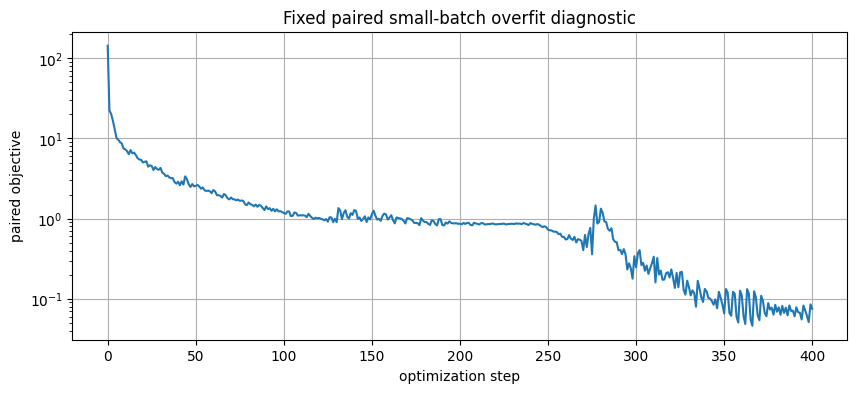

In [23]:
FIXED_PAIR_OVERFIT_NUM_WINDOWS = min(BATCH_SIZE, 16)
FIXED_PAIR_OVERFIT_NUM_STEPS = 400
FIXED_PAIR_OVERFIT_PRINT_EVERY = 25
FIXED_PAIR_OVERFIT_SEED = TRAIN_PAIR_SEED + 100000

fixed_pair_indices = np.linspace(0, len(train_dataset) - 1, FIXED_PAIR_OVERFIT_NUM_WINDOWS, dtype=int)
fixed_pair_base_window = collate_windows([train_dataset[int(index)] for index in fixed_pair_indices])
fixed_pair_base_window = window_batch_to(fixed_pair_base_window, DEVICE, dtype=MODEL_DTYPE)

fixed_pair_generator = make_augmentation_generator(FIXED_PAIR_OVERFIT_SEED)
fixed_pair_positive_window, fixed_pair_negative_window, _, _ = make_paired_windows(fixed_pair_base_window, generator=fixed_pair_generator)

fixed_pair_model_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
fixed_pair_previous_training_mode = model.training
fixed_pair_optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
fixed_pair_history = []

print("=" * 110)
print("FIXED PAIRED SMALL-BATCH OVERFIT DIAGNOSTIC")
print("=" * 110)
torch.cuda.empty_cache()
model.train()

for step in range(FIXED_PAIR_OVERFIT_NUM_STEPS + 1):
    fixed_pair_optimizer.zero_grad(set_to_none=True)

    positive_result = window_step(fixed_pair_positive_window)
    negative_result = window_step(fixed_pair_negative_window)
    loss, metrics = compute_paired_objective(fixed_pair_positive_window, positive_result.model_output, fixed_pair_negative_window, negative_result.model_output)
    fixed_pair_history.append(float(loss.detach()))

    if step == 0 or step % FIXED_PAIR_OVERFIT_PRINT_EVERY == 0 or step == FIXED_PAIR_OVERFIT_NUM_STEPS:
        print(f"step {step:4d}/{FIXED_PAIR_OVERFIT_NUM_STEPS} total={loss.item():9.6f} regular={metrics['loss_regular']:9.6f} pair={metrics['loss_pair']:9.6f}")

    if step == FIXED_PAIR_OVERFIT_NUM_STEPS:
        break

    loss.backward()
    if GRADIENT_CLIP_NORM is not None:
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
    fixed_pair_optimizer.step()

fixed_pair_fraction_remaining = fixed_pair_history[-1] / fixed_pair_history[0]

print()
print(f"Initial loss: {fixed_pair_history[0]:.6f}")
print(f"Final loss:   {fixed_pair_history[-1]:.6f}")
print(f"Remaining:    {100.0 * fixed_pair_fraction_remaining:.2f}% of initial loss")
print("FIXED PAIRED OVERFIT CHECK:", "PASS" if fixed_pair_fraction_remaining < 0.10 else "FAIL/WARNING")

plt.figure(figsize=(10, 4))
plt.plot(fixed_pair_history)
plt.yscale("log")
plt.xlabel("optimization step")
plt.ylabel("paired objective")
plt.title("Fixed paired small-batch overfit diagnostic")
plt.grid(True)
plt.show()

model.load_state_dict(fixed_pair_model_state)
model.train(fixed_pair_previous_training_mode)
model.zero_grad(set_to_none=True)

del fixed_pair_optimizer
del fixed_pair_model_state
torch.cuda.empty_cache()

## 13. Reversible stochastic learnability test (16 physical training windows, held-out fine/coarse probes)

This test uses **the model weights already initialized in Cell 12** (`scratch`, `weights`, or `resume`). It starts a separate fresh AdamW optimizer, trains temporarily on fixed physical windows with resampled perturbations, then restores the initial model and random states. It does not modify the full-training optimizer or the selected initialization mode.


step    0/500 | train=nan grad=nan | fine: total=5.282, original=0.193, pair=0.509, weighted_pair=5.089, rot=15.7° | coarse: total=26.387, original=1.427, pair=2.496, weighted_pair=24.960, rot=78.0°
step   25/500 | train=9.7625 grad=71.77 | fine: total=4.859, original=0.199, pair=0.466, weighted_pair=4.660, rot=17.0° | coarse: total=23.408, original=1.464, pair=2.194, weighted_pair=21.944, rot=79.2°
step   50/500 | train=16.6682 grad=78.77 | fine: total=4.401, original=0.190, pair=0.421, weighted_pair=4.211, rot=17.4° | coarse: total=24.335, original=1.428, pair=2.291, weighted_pair=22.907, rot=78.3°
step   75/500 | train=11.0793 grad=101.28 | fine: total=4.632, original=0.234, pair=0.440, weighted_pair=4.398, rot=18.2° | coarse: total=21.898, original=1.482, pair=2.042, weighted_pair=20.416, rot=79.0°
step  100/500 | train=9.9037 grad=91.98 | fine: total=4.345, original=0.205, pair=0.414, weighted_pair=4.140, rot=16.8° | coarse: total=22.585, original=1.426, pair=2.116, weighted_pair=

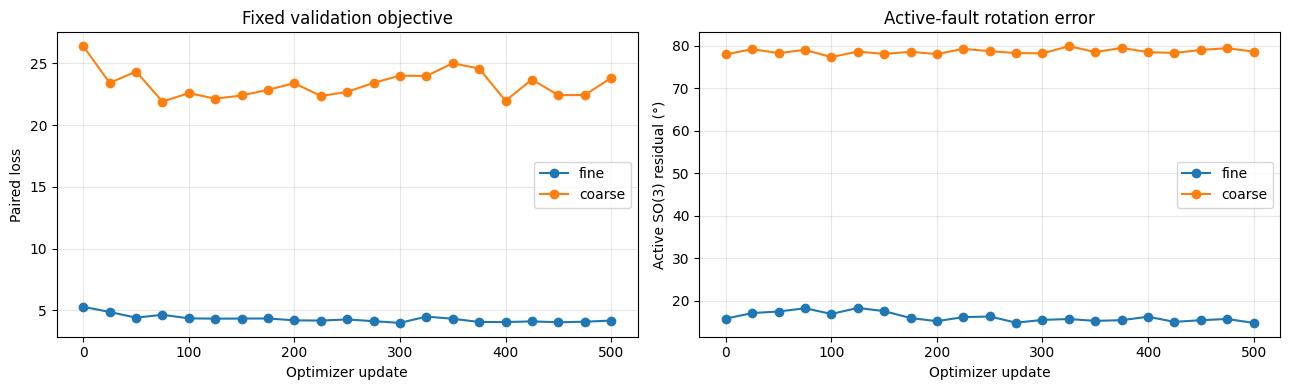

Stochastic run restored weights model weights and RNG; full optimizer remains unchanged.


In [50]:
STOCHASTIC_PAIR_NUM_WINDOWS = min(BATCH_SIZE, 16)
STOCHASTIC_PAIR_NUM_STEPS = 500
STOCHASTIC_PAIR_PRINT_EVERY = 25
STOCHASTIC_PAIR_TRAIN_SEED, STOCHASTIC_PAIR_EVAL_SEED = TRAIN_PAIR_SEED + 200000, VALIDATION_PAIR_SEED + 300000
PAIR_GATE_THRESHOLD = 0.75
PAIRED_STOCHASTIC_GATE_PASSED = None
STOCHASTIC_PAIR_HISTORY = []

if RUN_STOCHASTIC_PAIR_TEST:
    import random
    import copy
    saved_model = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    saved_training = model.training
    saved_torch_rng = torch.get_rng_state().clone()
    saved_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None
    saved_numpy_rng, saved_python_rng = np.random.get_state(), random.getstate()
    eval_indices = np.linspace(0, len(val_dataset) - 1, STOCHASTIC_PAIR_NUM_WINDOWS, dtype=int)
    training_indices = np.linspace(0, len(train_dataset) - 1, STOCHASTIC_PAIR_NUM_WINDOWS, dtype=int)
    base_train = window_batch_to(collate_windows([train_dataset[int(i)] for i in training_indices]), DEVICE, dtype=MODEL_DTYPE)
    base_val = window_batch_to(collate_windows([val_dataset[int(i)] for i in eval_indices]), DEVICE, dtype=MODEL_DTYPE)
    fixed_pairs = {}
    for label, probability, seed in (('fine', 0.0, STOCHASTIC_PAIR_EVAL_SEED), ('coarse', 1.0, STOCHASTIC_PAIR_EVAL_SEED + 1)):
        p, n, _, _ = make_paired_windows(base_val, generator=make_augmentation_generator(seed), coarse_probability=probability)
        fixed_pairs[label] = (p, n)
    try:
        # The model already contains scratch, warm-start, or resumed weights from Cell 12.
        # Fresh probe optimizer; the original model and RNG are restored below.
        probe_optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        generator = make_augmentation_generator(STOCHASTIC_PAIR_TRAIN_SEED)

        def evaluate_stochastic_fixed_65():
            model.eval()
            result = {}
            with torch.no_grad():
                for label, (positive, negative) in fixed_pairs.items():
                    p_out = window_step(positive).model_output
                    n_out = window_step(negative).model_output
                    total, metrics = compute_paired_objective(positive, p_out, negative, n_out)
                    active_errors = []
                    for window, output in ((positive, p_out), (negative, n_out)):
                        for key in CALIBRATION_KEYS:
                            target_xi, _ = correction_target(window, key)
                            active = torch.linalg.vector_norm(target_xi[:, :3], dim=-1) > 1e-3
                            if bool(active.any()):
                                active_errors.append(torch.rad2deg(rotation_geodesic_rad_65(output.predictions[key].delta_xi[active, :3], target_xi[active, :3])))
                    active_rot_deg = float(torch.cat(active_errors).mean()) if active_errors else float('nan')
                    result[label] = {'total': float(total.detach()), 'regular': metrics['loss_regular'], 'pair': metrics['loss_pair'], 'rot': float(np.mean([metrics[f'mean/{key}/rotation_error_deg'] for key in CALIBRATION_KEYS])), 'active_rot': active_rot_deg}
            return result

        for step in range(STOCHASTIC_PAIR_NUM_STEPS + 1):
            if step:
                model.train()
                positive, negative, _, _ = make_paired_windows(base_train, generator=generator)
                probe_optimizer.zero_grad(set_to_none=True)
                p_result, n_result = window_step(positive), window_step(negative)
                loss, _ = compute_paired_objective(positive, p_result.model_output, negative, n_result.model_output)
                if not torch.isfinite(loss):
                    raise FloatingPointError(f'Stochastic objective became non-finite at step {step}: {loss}')
                loss.backward()
                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM) if GRADIENT_CLIP_NORM is not None else torch.tensor(float('nan'))
                probe_optimizer.step()
                last_train_loss = float(loss.detach())
                del positive, negative, p_result, n_result, loss
            else:
                last_train_loss, grad_norm = float('nan'), float('nan')
            if step == 0 or step % STOCHASTIC_PAIR_PRINT_EVERY == 0 or step == STOCHASTIC_PAIR_NUM_STEPS:
                values = evaluate_stochastic_fixed_65()
                row = {'step': step, 'training_loss': last_train_loss, 'grad_norm': float(grad_norm), **{f'{kind}_{name}': val for kind, metrics in values.items() for name, val in metrics.items()}}
                STOCHASTIC_PAIR_HISTORY.append(row)
                # print(f'step {step:4d}/{STOCHASTIC_PAIR_NUM_STEPS} | train={last_train_loss:.4f} grad={float(grad_norm):.2f} | fine loss={values["fine"]["total"]:.3f} active_rot={values["fine"]["active_rot"]:.1f}° | coarse loss={values["coarse"]["total"]:.3f} active_rot={values["coarse"]["active_rot"]:.1f}°', flush=True)
                print(
                    f'step {step:4d}/{STOCHASTIC_PAIR_NUM_STEPS} | train={last_train_loss:.4f} grad={float(grad_norm):.2f} | '
                    f'fine: total={values["fine"]["total"]:.3f}, original={values["fine"]["regular"]:.3f}, pair={values["fine"]["pair"]:.3f}, weighted_pair={PAIR_LOSS_WEIGHT * values["fine"]["pair"]:.3f}, rot={values["fine"]["active_rot"]:.1f}° | '
                    f'coarse: total={values["coarse"]["total"]:.3f}, original={values["coarse"]["regular"]:.3f}, pair={values["coarse"]["pair"]:.3f}, weighted_pair={PAIR_LOSS_WEIGHT * values["coarse"]["pair"]:.3f}, rot={values["coarse"]["active_rot"]:.1f}°',
                    flush=True,
                )

        first, last = STOCHASTIC_PAIR_HISTORY[0], STOCHASTIC_PAIR_HISTORY[-1]
        # The gate is a diagnostic only, not a hidden override of RUN_FULL_TRAINING.
        PAIRED_STOCHASTIC_GATE_PASSED = last['fine_total'] < PAIR_GATE_THRESHOLD * first['fine_total'] and last['coarse_total'] < PAIR_GATE_THRESHOLD * first['coarse_total']
        print('Stochastic fixed-val fine/coarse gate:', 'PASS' if PAIRED_STOCHASTIC_GATE_PASSED else 'INCONCLUSIVE (inspect learning curves)')
        fig, axes = plt.subplots(1, 2, figsize=(13, 4))
        for label in ('fine', 'coarse'):
            axes[0].plot([row['step'] for row in STOCHASTIC_PAIR_HISTORY], [row[f'{label}_total'] for row in STOCHASTIC_PAIR_HISTORY], '-o', label=label)
            axes[1].plot([row['step'] for row in STOCHASTIC_PAIR_HISTORY], [row[f'{label}_active_rot'] for row in STOCHASTIC_PAIR_HISTORY], '-o', label=label)
        axes[0].set(title='Fixed validation objective', xlabel='Optimizer update', ylabel='Paired loss')
        axes[1].set(title='Active-fault rotation error', xlabel='Optimizer update', ylabel='Active SO(3) residual (°)')
        for ax in axes:
            ax.grid(alpha=0.3)
            ax.legend()
        plt.tight_layout()
        plt.show()
    finally:
        model.load_state_dict(saved_model, strict=True)
        model.train(saved_training)
        optimizer.zero_grad(set_to_none=True)
        torch.set_rng_state(saved_torch_rng)
        if saved_cuda_rng is not None:
            torch.cuda.set_rng_state_all(saved_cuda_rng)
        np.random.set_state(saved_numpy_rng)
        random.setstate(saved_python_rng)
        del saved_model
        import gc
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
    print(f'Stochastic run restored {INITIALIZATION_MODE} model weights and RNG; full optimizer remains unchanged.')
else:
    print('Stochastic paired experiment disabled; full run remains separately selectable.')


In [39]:
from obscalib.augmentations.prior_perturbation import apply_prior_perturbation

TOKEN_SENSITIVITY_NUM_WINDOWS = min(BATCH_SIZE, 8)
TOKEN_SENSITIVITY_ROTATION_RAD = np.deg2rad(5.0)
TOKEN_SENSITIVITY_TRANSLATION_M = 0.02
TOKEN_SENSITIVITY_SEED = TRAIN_PAIR_SEED + 910000

token_sensitivity_indices = np.linspace(0, len(train_dataset) - 1, TOKEN_SENSITIVITY_NUM_WINDOWS, dtype=int)
token_sensitivity_base_window = collate_windows([train_dataset[int(index)] for index in token_sensitivity_indices])
token_sensitivity_base_window = window_batch_to(token_sensitivity_base_window, DEVICE, dtype=MODEL_DTYPE)

token_sensitivity_generator = make_augmentation_generator(TOKEN_SENSITIVITY_SEED)
token_sensitivity_window = context_augmentation_pipeline(token_sensitivity_base_window, generator=token_sensitivity_generator).augmented_window
token_sensitivity_truth = token_sensitivity_window.current_calibration

component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z")

print("=" * 100)
print("SPATIAL CALIBRATION -> TOKEN SENSITIVITY")
print("=" * 100)
print(f"{'calibration':12s} {'component':10s} {'mean |Δx|':>14s} {'RMS Δx':>14s} {'max |Δx|':>14s} {'RMS/signal':>14s}")

for calibration_id, calibration_key in enumerate(CALIBRATION_KEYS):
    batch_size = token_sensitivity_truth[calibration_key].transform.shape[0]

    for component_index, component_name in enumerate(component_names):
        delta_xi_by_key = {key: torch.zeros(batch_size, 6, device=DEVICE, dtype=MODEL_DTYPE) for key in CALIBRATION_KEYS}
        delta_tau_by_key = {key: torch.zeros(batch_size, 1, device=DEVICE, dtype=MODEL_DTYPE) for key in CALIBRATION_KEYS}
        delta_xi_by_key[calibration_key][:, component_index] = TOKEN_SENSITIVITY_ROTATION_RAD if component_index < 3 else TOKEN_SENSITIVITY_TRANSLATION_M

        positive_calibration = apply_prior_perturbation(token_sensitivity_truth, delta_xi_by_key, delta_tau_by_key)
        negative_calibration = apply_prior_perturbation(token_sensitivity_truth, {key: -value for key, value in delta_xi_by_key.items()}, delta_tau_by_key)

        positive_tokens = tokenizer(geometry_processor(token_sensitivity_window.streams, token_sensitivity_window.metadata, positive_calibration), None)
        negative_tokens = tokenizer(geometry_processor(token_sensitivity_window.streams, token_sensitivity_window.metadata, negative_calibration), None)

        torch.testing.assert_close(positive_tokens.token_mask, negative_tokens.token_mask)
        torch.testing.assert_close(positive_tokens.calibration_ids, negative_tokens.calibration_ids)

        calibration_mask = positive_tokens.token_mask & (positive_tokens.calibration_ids == calibration_id)
        positive_measurements = positive_tokens.x[..., :MEASUREMENT_DIM][calibration_mask]
        negative_measurements = negative_tokens.x[..., :MEASUREMENT_DIM][calibration_mask]
        difference = positive_measurements - negative_measurements

        mean_abs = difference.abs().mean().item()
        rms = difference.square().mean().sqrt().item()
        maximum = difference.abs().max().item()
        signal_rms = (0.5 * (positive_measurements.square() + negative_measurements.square())).mean().sqrt().item()
        relative_rms = rms / max(signal_rms, 1e-12)

        print(f"{calibration_key:12s} {component_name:10s} {mean_abs:14.6e} {rms:14.6e} {maximum:14.6e} {relative_rms:14.6e}")

del token_sensitivity_base_window
del token_sensitivity_window
torch.cuda.empty_cache()

SPATIAL CALIBRATION -> TOKEN SENSITIVITY
calibration  component       mean |Δx|         RMS Δx       max |Δx|     RMS/signal
imu          phi_x        1.500774e-01   4.961924e-01   2.386278e+00   1.736864e-01
imu          phi_y        1.511438e-01   4.958833e-01   2.386277e+00   1.735781e-01
imu          phi_z        1.524938e-02   6.210872e-02   1.855107e+00   2.174043e-02
imu          rho_x        0.000000e+00   0.000000e+00   0.000000e+00   0.000000e+00
imu          rho_y        0.000000e+00   0.000000e+00   0.000000e+00   0.000000e+00
imu          rho_z        0.000000e+00   0.000000e+00   0.000000e+00   0.000000e+00
lidar        phi_x        5.239260e-04   1.362165e-03   2.975069e-02   8.602663e-03
lidar        phi_y        7.334019e-03   2.757858e-02   2.715913e-01   1.741707e-01
lidar        phi_z        7.404839e-03   2.758952e-02   2.715911e-01   1.742399e-01
lidar        rho_x        3.321525e-05   1.469670e-04   1.918331e-03   9.281607e-04
lidar        rho_y        3.292025e

In [40]:
from obscalib.calibration.context import calibration_state_to_context

model.eval()

print("=" * 90)
print("CALIBRATION CONTEXT / QUERY DIAGNOSTIC")
print("=" * 90)
print("Pooler calibration context dim:", model.pooler.calibration_context_dim)
print()

with torch.inference_mode():
    for calibration_key in CALIBRATION_KEYS:
        positive_context = calibration_state_to_context(semantic_positive_window.current_calibration[calibration_key])
        negative_context = calibration_state_to_context(semantic_negative_window.current_calibration[calibration_key])
        context_difference_rms = (positive_context - negative_context).square().mean().sqrt().item()

        print(calibration_key)
        print("  context Δ RMS:", context_difference_rms)

        if model.pooler.context_encoder is None:
            print("  encoded-query diagnostic: disabled because calibration_context_dim=0")
        else:
            positive_query = model.pooler.context_encoder(positive_context)
            negative_query = model.pooler.context_encoder(negative_context)
            difference = positive_query - negative_query
            query_difference_rms = difference.square().mean().sqrt().item()
            query_rms = 0.5 * (positive_query.square().mean().sqrt().item() + negative_query.square().mean().sqrt().item())

            print("  encoded-query Δ RMS:", query_difference_rms)
            print("  encoded-query Δ / query RMS:", query_difference_rms / max(query_rms, 1e-12))

        print()

CALIBRATION CONTEXT / QUERY DIAGNOSTIC
Pooler calibration context dim: 0

imu
  context Δ RMS: 0.30106276273727417
  encoded-query diagnostic: disabled because calibration_context_dim=0

lidar
  context Δ RMS: 1.516151785850525
  encoded-query diagnostic: disabled because calibration_context_dim=0

lidar_right
  context Δ RMS: 0.5178542733192444
  encoded-query diagnostic: disabled because calibration_context_dim=0



## 14. Paired epoch runner


In [42]:
def run_paired_epoch(loader, *, training: bool, pair_generator: torch.Generator, global_step: int):
    model.train(training)

    metric_sums = {}
    num_samples = 0
    start_time = time.perf_counter()

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    grad_context = torch.enable_grad() if training else torch.no_grad()

    with grad_context:
        for batch_index, base_window in enumerate(loader):
            base_window = window_batch_to(base_window, DEVICE, dtype=MODEL_DTYPE)
            positive_window, negative_window, _, _ = make_paired_windows(base_window, generator=pair_generator)
            # positive_window, negative_window, truth_window, _, _ = make_paired_windows(base_window, generator=pair_generator, return_truth_window=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            positive_result = window_step(positive_window)
            negative_result = window_step(negative_window)
            # truth_result = window_step(truth_window)

            loss, metrics = compute_paired_objective(
                positive_window,
                positive_result.model_output,
                negative_window,
                negative_result.model_output,
                # truth_window,
                # truth_result.model_output,
            )

            if training:
                loss.backward()
                if GRADIENT_CLIP_NORM is not None:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
                optimizer.step()
                global_step += 1

            batch_size = next(iter(positive_window.streams.values())).values.shape[0]
            accumulate_metrics(metric_sums, metrics, batch_size)
            num_samples += batch_size

            if training and PRINT_EVERY_BATCHES > 0 and (batch_index + 1) % PRINT_EVERY_BATCHES == 0:
                print(f"batch {batch_index + 1:5d}/{len(loader):5d} loss={loss.item():.6f}")

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.empty_cache()

    elapsed_s = time.perf_counter() - start_time
    epoch_metrics = normalize_metrics(metric_sums, num_samples)
    epoch_metrics["epoch_time_s"] = elapsed_s
    epoch_metrics["samples_per_s"] = num_samples / elapsed_s

    return epoch_metrics, global_step


## 15. Checkpoint paths and experiment snapshot


In [43]:
RUN_DIR = ROOT / 'runs' / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH = RUN_DIR / 'best.pt', RUN_DIR / 'last.pt'
METRICS_PATH = RUN_DIR / 'metrics.jsonl'
if INITIALIZATION_MODE == 'weights' and Path(INITIAL_WEIGHTS_CHECKPOINT).resolve() in (BEST_CHECKPOINT_PATH.resolve(), LAST_CHECKPOINT_PATH.resolve()):
    raise ValueError('Weights-only initialization must use a new RUN_NAME: source and output checkpoint paths coincide.')
EXPERIMENT_SNAPSHOT = {
    'run_name': RUN_NAME,
    'initialization_mode': INITIALIZATION_MODE,
    'initial_weights_checkpoint': str(INITIAL_WEIGHTS_CHECKPOINT) if INITIALIZATION_MODE == 'weights' else None,
    'resume_checkpoint': str(RESUME_CHECKPOINT) if INITIALIZATION_MODE == 'resume' else None,
    'calibration_keys': CALIBRATION_KEYS,
    'architecture': 'PooledCalibrationModel_3d_se3_log',
    'paired_prior_training': True,
    'pair_loss_weight': PAIR_LOSS_WEIGHT,
    'rotation_supervision': ROTATION_SUPERVISION_MODE,
    'fine_student_t_max_deg': FINE_ROTATION_MAX_DEG,
    'fine_student_t_scale_deg': FINE_ROTATION_SCALE_DEG,
    'coarse_uniform_min_deg': COARSE_ROTATION_MIN_DEG,
    'coarse_uniform_max_deg': COARSE_ROTATION_MAX_DEG,
    'coarse_prior_probability': COARSE_PRIOR_PROBABILITY,
    'kaist_reference_tau_s': REFINED_TAU_BY_SENSOR_S,
    'frame_randomization': False,
    'true_calibration_augmentation': True,
    'measurement_noise': False,
    'numeric_calibration_context_in_pooler': False,
    'numeric_calibration_context_in_head': False,
}
train_pair_generator = make_augmentation_generator(TRAIN_PAIR_SEED)


## 16. Initialize the full-training state (independent of stochastic preflight)

Model weights were already initialized in Cell 12, so the stochastic test and the full run use the same starting model. Only when `INITIALIZATION_MODE='resume'` does this cell restore the existing optimizer, scheduler, epoch, global step, and RNG/generator states. `scratch` and `weights` begin at epoch 0, with freshly created optimizer and scheduler.


In [44]:
start_epoch, global_step, best_validation_loss = 0, 0, float('inf')
if INITIALIZATION_MODE == 'resume':
    # A true resume, including optimizer/scheduler and train-sampler generator, is intentionally
    # different from the scratch defaults. Resume only from this architecture/run.
    checkpoint = load_training_checkpoint(
        RESUME_CHECKPOINT, model=model, optimizer=optimizer, scheduler=scheduler,
        map_location=DEVICE, restore_rng_state=True,
        generators={'train_shuffle': train_shuffle_generator, 'train_pair': train_pair_generator},
    )
    start_epoch = int(checkpoint.get('epoch', 0))
    global_step = int(checkpoint.get('global_step', 0))
    best_validation_loss = float(checkpoint.get('extra_state', {}).get('best_validation_loss', float('inf')))
    print('Restored model, optimizer, scheduler and RNG from:', RESUME_CHECKPOINT, '| epoch:', start_epoch, '| step:', global_step)
elif INITIALIZATION_MODE == 'weights':
    print('Weights-only initialization: model loaded in Cell 12; optimizer/scheduler are fresh, epoch=0, step=0.')
else:
    print('Scratch initialization: fresh model, optimizer/scheduler, epoch=0, step=0.')


Weights-only initialization: model loaded in Cell 12; optimizer/scheduler are fresh, epoch=0, step=0.


## 17. Full mixed-distribution training

`RUN_FULL_TRAINING` is independent of `RUN_STOCHASTIC_PAIR_TEST`. A new `scratch` or `weights` experiment starts at epoch 0 and writes new metrics/checkpoints under `RUN_NAME`; `resume` appends to that run using the saved optimizer/scheduler state. An existing output checkpoint cannot be silently overwritten in a new run.


In [45]:
torch.cuda.empty_cache()

In [47]:
history = []
if RUN_FULL_TRAINING and REQUIRE_STOCHASTIC_GATE and PAIRED_STOCHASTIC_GATE_PASSED is not True:
    raise RuntimeError('Stochastic gate requested but not passed. Disable REQUIRE_STOCHASTIC_GATE or rerun the diagnostic.')
if RUN_FULL_TRAINING:
    if INITIALIZATION_MODE != 'resume' and (BEST_CHECKPOINT_PATH.exists() or LAST_CHECKPOINT_PATH.exists()):
        raise FileExistsError(f'Fresh training would overwrite checkpoints in {RUN_DIR}. Choose a new RUN_NAME, or INITIALIZATION_MODE="resume".')
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    with MetricsLogger(METRICS_PATH, append=(INITIALIZATION_MODE == 'resume')) as logger:
        if INITIALIZATION_MODE != 'resume':
            logger.log_config(model_config, name="model_config")
            logger.log_config(context_augmentation_config, name="context_augmentation_config")
            logger.log_config(fine_prior_config, name="fine_prior_config")
            logger.log_config(coarse_prior_config, name="coarse_prior_config")
            logger.log_config(
                {
                    "device": str(DEVICE),
                    "batch_size": BATCH_SIZE,
                    "window_duration_s": WINDOW_DURATION_S,
                    "window_stride_s": WINDOW_STRIDE_S,
                    "learning_rate": LEARNING_RATE,
                    "weight_decay": WEIGHT_DECAY,
                    "train_sequences": TRAIN_NAMES,
                    "validation_sequences": VAL_NAMES,
                    "test_sequences": TEST_NAMES,
                    **EXPERIMENT_SNAPSHOT,
                },
                name="experiment",
            )

        for epoch in range(start_epoch, NUM_EPOCHS):
            print()
            print("=" * 80)
            print(f"Epoch {epoch + 1}/{NUM_EPOCHS}")

            train_metrics, global_step = run_paired_epoch(train_loader, training=True, pair_generator=train_pair_generator, global_step=global_step)

            # Recreate validation generator from the same seed every epoch so validation pairs stay fixed.
            val_pair_generator = make_augmentation_generator(VALIDATION_PAIR_SEED)
            val_metrics, _ = run_paired_epoch(val_loader, training=False, pair_generator=val_pair_generator, global_step=global_step)

            scheduler.step(val_metrics["loss_total"])
            learning_rate = optimizer.param_groups[0]["lr"]

            row = {
                "epoch": epoch + 1,
                "global_step": global_step,
                "learning_rate": learning_rate,
                **{f"train/{key}": value for key, value in train_metrics.items()},
                **{f"val/{key}": value for key, value in val_metrics.items()},
            }
            history.append(row)

            logger.log_metrics({**train_metrics, "learning_rate": learning_rate}, split="train", epoch=epoch + 1, step=global_step)
            logger.log_metrics(val_metrics, split="validation", epoch=epoch + 1, step=global_step)

            print(
                f"train total={train_metrics['loss_total']:.6f} regular={train_metrics['loss_regular']:.6f} pair={train_metrics['loss_pair']:.6f}| "
                f"val total={val_metrics['loss_total']:.6f} regular={val_metrics['loss_regular']:.6f} pair={val_metrics['loss_pair']:.6f}| "
                f"lr={learning_rate:.3e}"
            )

            if val_metrics["loss_total"] < best_validation_loss:
                best_validation_loss = val_metrics["loss_total"]
                save_training_checkpoint(
                    BEST_CHECKPOINT_PATH,
                    model=model,
                    optimizer=optimizer,
                    scheduler=scheduler,
                    epoch=epoch + 1,
                    global_step=global_step,
                    metrics=val_metrics,
                    generators={"train_shuffle": train_shuffle_generator, "train_pair": train_pair_generator},
                    extra_state={"best_validation_loss": best_validation_loss},
                )
                print("Saved new best checkpoint.")

            if (epoch + 1) % CHECKPOINT_EVERY_EPOCHS == 0 or epoch + 1 == NUM_EPOCHS:
                save_training_checkpoint(
                    LAST_CHECKPOINT_PATH,
                    model=model,
                    optimizer=optimizer,
                    scheduler=scheduler,
                    epoch=epoch + 1,
                    global_step=global_step,
                    metrics=val_metrics,
                    generators={"train_shuffle": train_shuffle_generator, "train_pair": train_pair_generator},
                    extra_state={"best_validation_loss": best_validation_loss},
                )
                print("Saved last checkpoint.")
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
                torch.cuda.empty_cache()
else:
    print('Full training disabled by RUN_FULL_TRAINING=False; stochastic gate is advisory by default.')



Epoch 1/200
train total=299.885427 regular=8.352570 pair=29.153286| val total=273.761214 regular=7.793868 pair=26.596734| lr=7.500e-05
Saved new best checkpoint.

Epoch 2/200
train total=257.575264 regular=8.780440 pair=24.879482| val total=224.602017 regular=13.501239 pair=21.110078| lr=7.500e-05
Saved new best checkpoint.

Epoch 3/200
train total=165.371029 regular=10.847305 pair=15.452372| val total=142.344290 regular=15.817777 pair=12.652651| lr=7.500e-05
Saved new best checkpoint.
Saved last checkpoint.

Epoch 4/200
train total=88.286128 regular=7.169941 pair=8.111619| val total=79.036490 regular=8.189450 pair=7.084704| lr=7.500e-05
Saved new best checkpoint.

Epoch 5/200
train total=57.033966 regular=5.171063 pair=5.186290| val total=52.815114 regular=5.745909 pair=4.706920| lr=7.500e-05
Saved new best checkpoint.

Epoch 6/200
train total=41.985037 regular=4.116464 pair=3.786857| val total=43.453306 regular=4.226244 pair=3.922706| lr=7.500e-05
Saved new best checkpoint.
Saved la

KeyboardInterrupt: 

## 18. Training curves


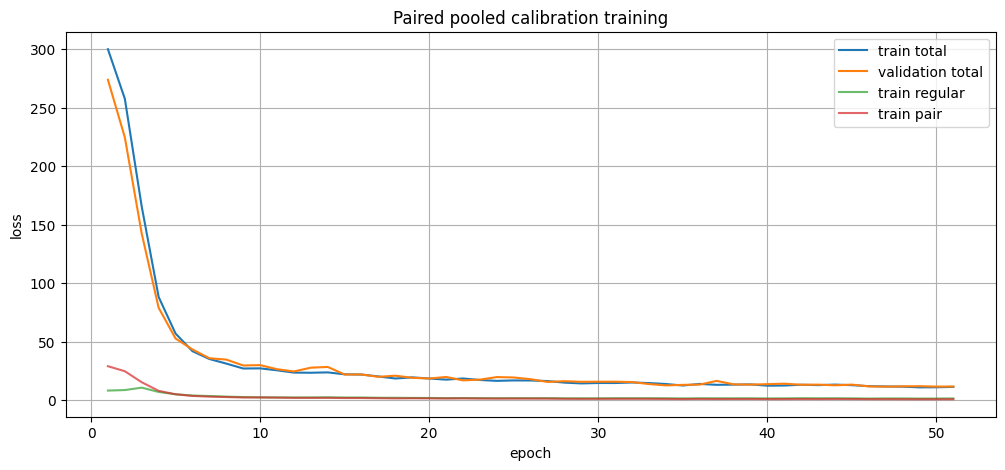

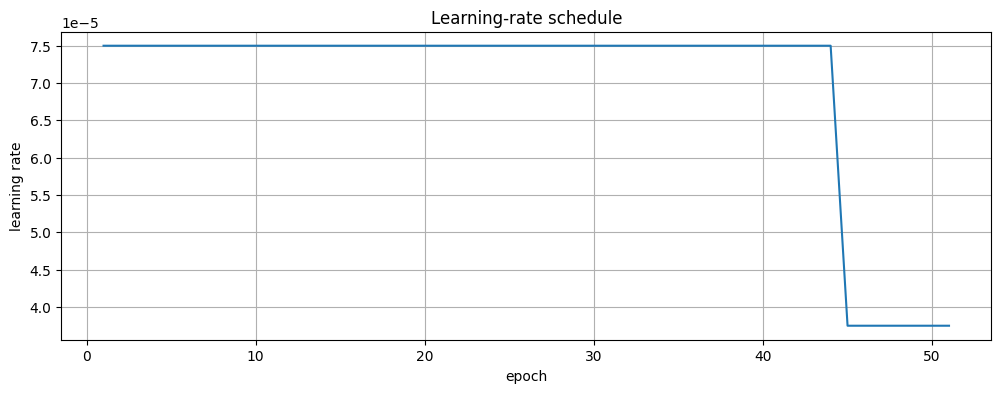

In [48]:
if history:
    epochs = [row["epoch"] for row in history]

    plt.figure(figsize=(12, 5))
    plt.plot(epochs, [row["train/loss_total"] for row in history], label="train total")
    plt.plot(epochs, [row["val/loss_total"] for row in history], label="validation total")
    plt.plot(epochs, [row["train/loss_regular"] for row in history], label="train regular", alpha=0.7)
    plt.plot(epochs, [row["train/loss_pair"] for row in history], label="train pair", alpha=0.7)
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title("Paired pooled calibration training")
    plt.grid(True)
    plt.legend()
    plt.show()

    plt.figure(figsize=(12, 4))
    plt.plot(epochs, [row["learning_rate"] for row in history])
    plt.xlabel("epoch")
    plt.ylabel("learning rate")
    plt.title("Learning-rate schedule")
    plt.grid(True)
    plt.show()
torch.cuda.empty_cache()

## 19. Evaluate the best checkpoint


In [49]:
if BEST_CHECKPOINT_PATH.exists():
    best_checkpoint = load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
    test_pair_generator = make_augmentation_generator(TEST_PAIR_SEED)
    test_metrics, _ = run_paired_epoch(test_loader, training=False, pair_generator=test_pair_generator, global_step=global_step)

    print("Best checkpoint epoch:", best_checkpoint.get("epoch"))
    print("Test metrics:")
    for key in sorted(test_metrics):
        print(f"  {key}: {test_metrics[key]:.6f}")
else:
    print("No best checkpoint exists yet.")


Best checkpoint epoch: 47
Test metrics:
  epoch_time_s: 355.647323
  loss_pair: 0.894848
  loss_regular: 1.744839
  loss_total: 10.693315
  loss_truth: 0.000000
  mean/imu/loss_rotation: 0.703934
  mean/imu/loss_time_offset: 0.128188
  mean/imu/loss_translation: 0.021570
  mean/imu/rotation_error_deg: 24.923566
  mean/imu/time_offset_error_ms: 9.836211
  mean/imu/translation_error_cm: 0.654087
  mean/lidar/loss_rotation: 0.754103
  mean/lidar/loss_time_offset: 0.265141
  mean/lidar/loss_translation: 0.022238
  mean/lidar/rotation_error_deg: 28.517252
  mean/lidar/time_offset_error_ms: 15.209884
  mean/lidar/translation_error_cm: 0.711902
  mean/lidar_right/loss_rotation: 0.791199
  mean/lidar_right/loss_time_offset: 0.278232
  mean/lidar_right/loss_translation: 0.020675
  mean/lidar_right/rotation_error_deg: 28.918385
  mean/lidar_right/time_offset_error_ms: 15.535390
  mean/lidar_right/translation_error_cm: 0.657893
  negative/imu/loss_rotation: 0.682378
  negative/imu/loss_time_offse

## 20. Select held-out windows for detailed visualization


In [50]:
VIS_SEQUENCE_NAME = "Urban38"
VIS_START_WINDOW = 0
VIS_NUM_WINDOWS = 100
VIS_BATCH_SIZE = 16

sequence_indices = [index for index in range(len(test_dataset)) if test_dataset.sequence_name_for_window(index) == VIS_SEQUENCE_NAME]

if not sequence_indices:
    raise ValueError(f"Sequence {VIS_SEQUENCE_NAME!r} is not present in test_dataset.")

selected_indices = sequence_indices[VIS_START_WINDOW : VIS_START_WINDOW + VIS_NUM_WINDOWS]

print("Sequence:", VIS_SEQUENCE_NAME)
print("Selected windows:", len(selected_indices))
print("Dataset indices:", selected_indices[0], "...", selected_indices[-1])


Sequence: Urban38
Selected windows: 100
Dataset indices: 0 ... 99


## 21. Collect deterministic paired predictions


In [51]:
def collect_paired_predictions(dataset, indices, *, batch_size, pair_seed):
    model.eval()
    pair_generator = make_augmentation_generator(pair_seed)

    collected = {
        calibration_key: {
            "positive_true_xi": [],
            "positive_predicted_xi": [],
            "positive_true_tau": [],
            "positive_predicted_tau": [],
            "negative_true_xi": [],
            "negative_predicted_xi": [],
            "negative_true_tau": [],
            "negative_predicted_tau": [],
        }
        for calibration_key in CALIBRATION_KEYS
    }

    with torch.no_grad():
        for start in range(0, len(indices), batch_size):
            batch_indices = indices[start : start + batch_size]
            base_window = collate_windows([dataset[index] for index in batch_indices])
            base_window = window_batch_to(base_window, DEVICE, dtype=MODEL_DTYPE)

            positive_window, negative_window, _, _ = make_paired_windows(base_window, generator=pair_generator)
            positive_result = window_step(positive_window)
            negative_result = window_step(negative_window)

            for calibration_key in CALIBRATION_KEYS:
                positive_true_xi, positive_true_tau = correction_target(positive_window, calibration_key)
                negative_true_xi, negative_true_tau = correction_target(negative_window, calibration_key)

                positive_prediction = positive_result.model_output.predictions[calibration_key]
                negative_prediction = negative_result.model_output.predictions[calibration_key]

                collected[calibration_key]["positive_true_xi"].append(positive_true_xi.detach().cpu())
                collected[calibration_key]["positive_predicted_xi"].append(positive_prediction.delta_xi.detach().cpu())
                collected[calibration_key]["positive_true_tau"].append(positive_true_tau.detach().cpu())
                collected[calibration_key]["positive_predicted_tau"].append(positive_prediction.delta_tau.detach().cpu())

                collected[calibration_key]["negative_true_xi"].append(negative_true_xi.detach().cpu())
                collected[calibration_key]["negative_predicted_xi"].append(negative_prediction.delta_xi.detach().cpu())
                collected[calibration_key]["negative_true_tau"].append(negative_true_tau.detach().cpu())
                collected[calibration_key]["negative_predicted_tau"].append(negative_prediction.delta_tau.detach().cpu())

    for calibration_key in CALIBRATION_KEYS:
        for field_name in collected[calibration_key]:
            collected[calibration_key][field_name] = torch.cat(collected[calibration_key][field_name], dim=0).numpy()

    return collected


if BEST_CHECKPOINT_PATH.exists():
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)

visualization_results = collect_paired_predictions(test_dataset, selected_indices, batch_size=VIS_BATCH_SIZE, pair_seed=VISUALIZATION_PAIR_SEED)


## 22. True vs predicted correction over windows


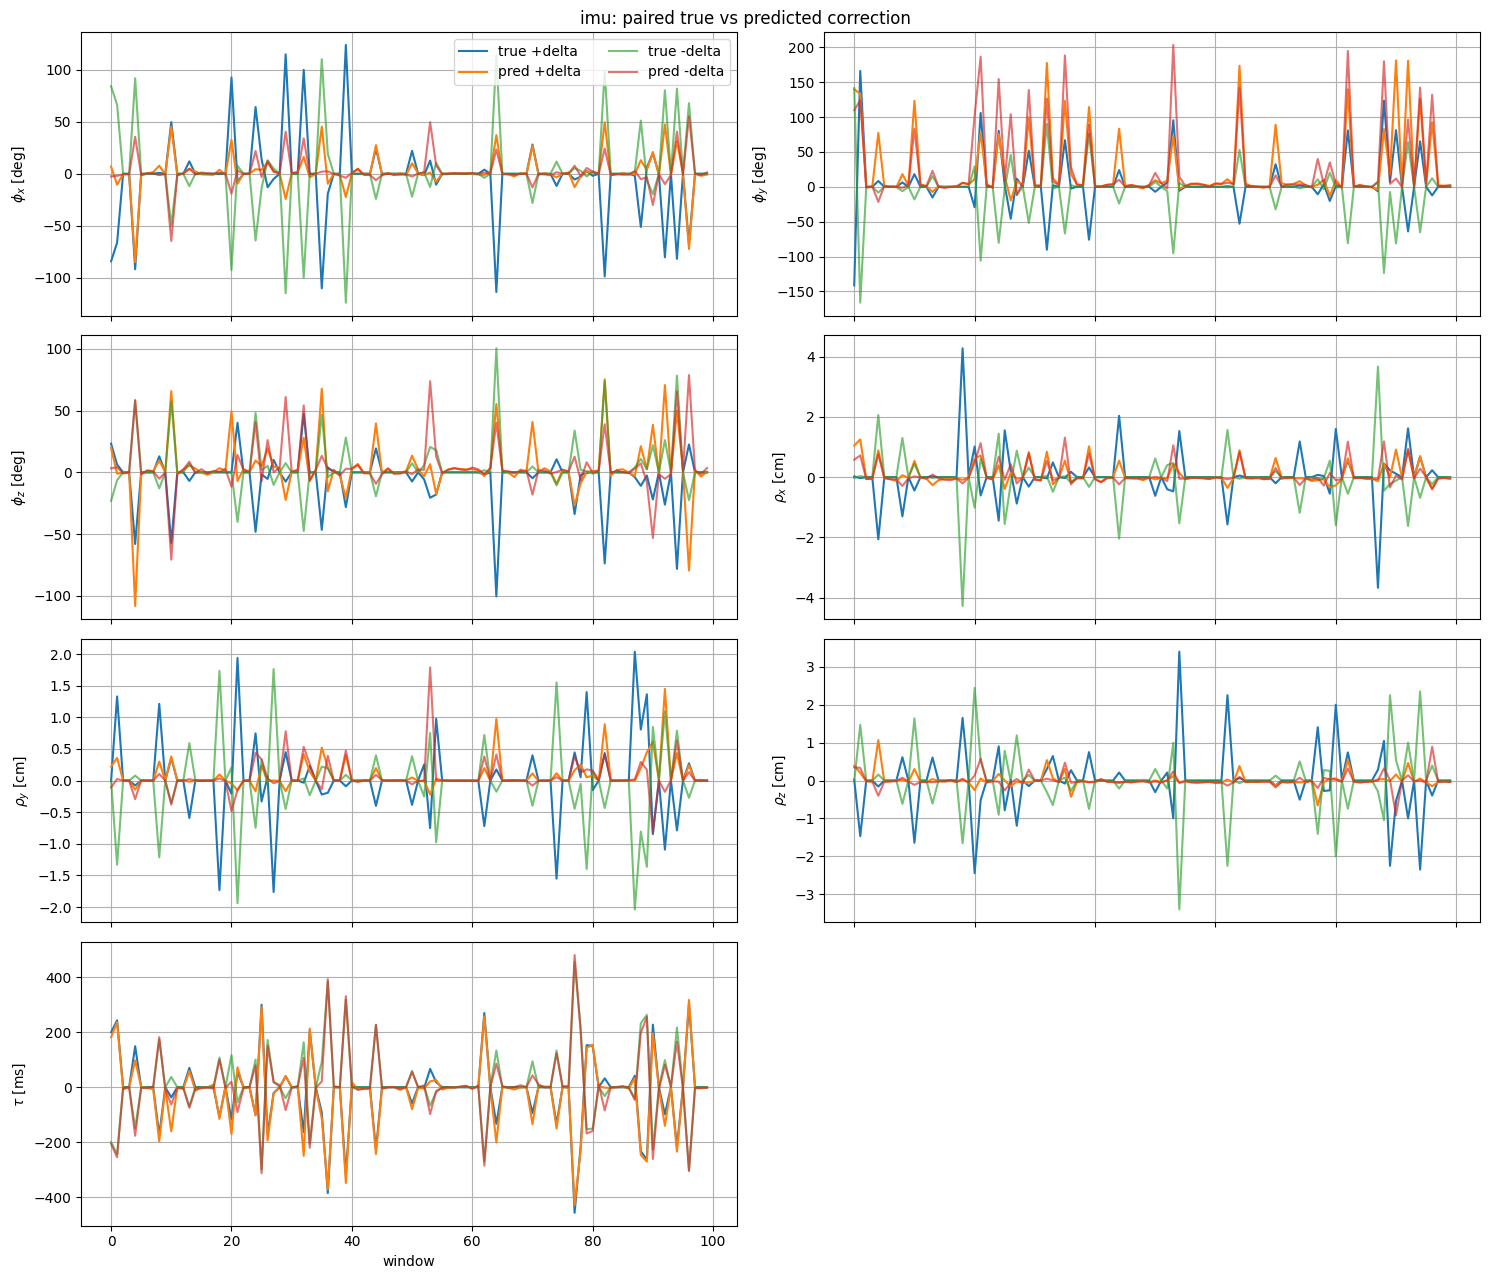

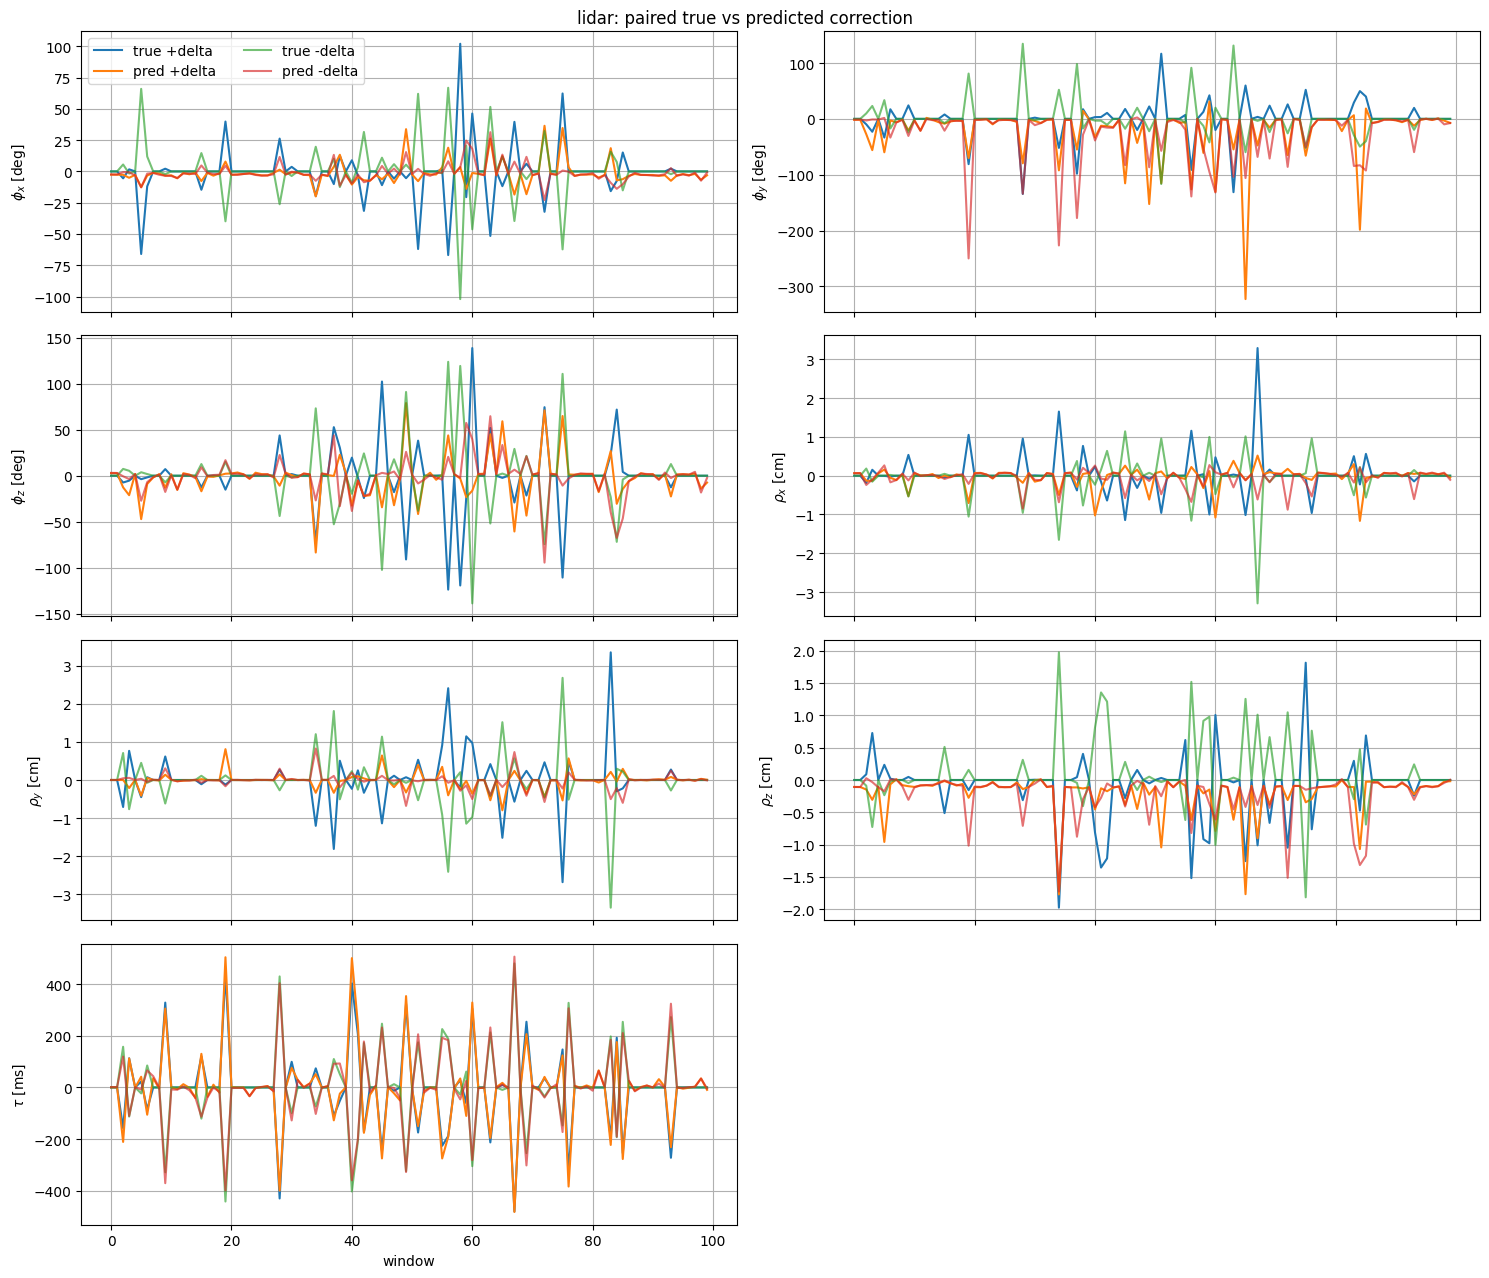

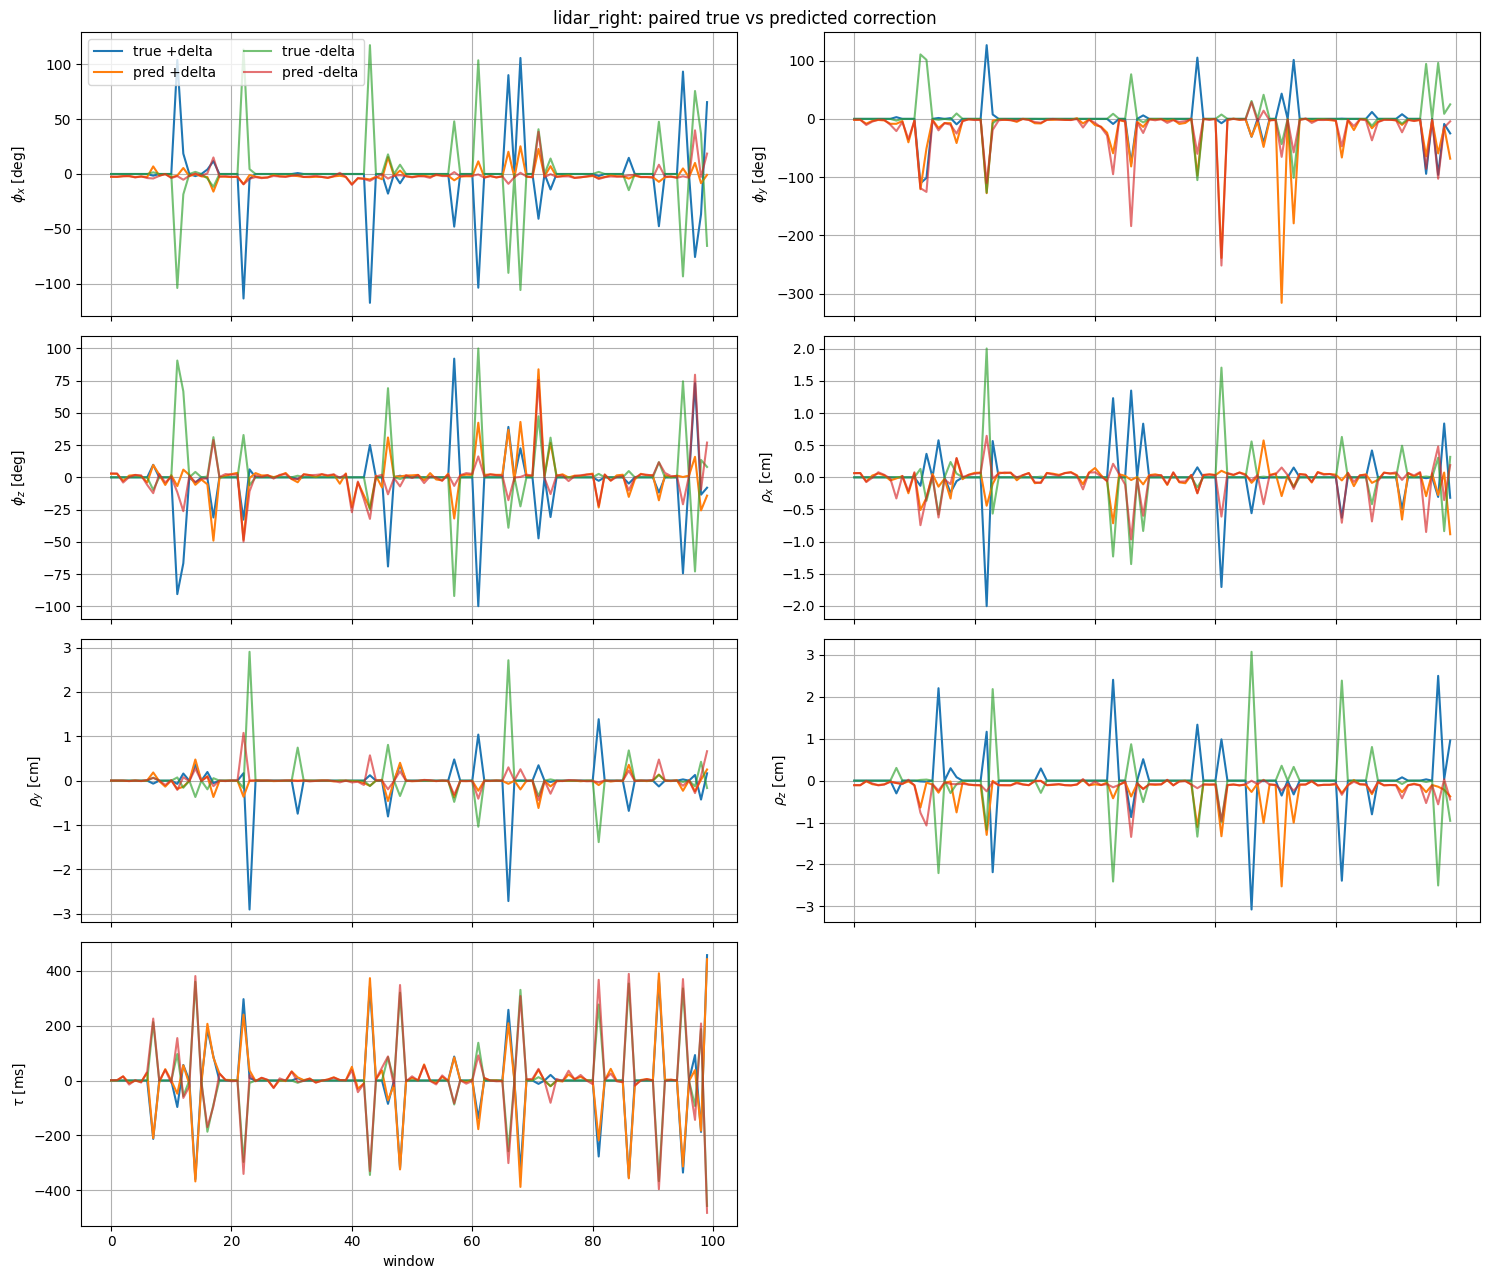

In [52]:
def physical_correction_values(xi, tau):
    return np.column_stack([np.rad2deg(xi[:, :3]), 100.0 * xi[:, 3:], 1000.0 * tau.reshape(-1)])


def plot_paired_true_vs_predicted(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    component_names = (r"$\phi_x$", r"$\phi_y$", r"$\phi_z$", r"$\rho_x$", r"$\rho_y$", r"$\rho_z$", r"$\tau$")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")
    x = np.arange(len(positive_true))

    fig, axes = plt.subplots(4, 2, figsize=(15, 13), sharex=True)
    axes = axes.ravel()

    for component_index in range(7):
        ax = axes[component_index]
        ax.plot(x, positive_true[:, component_index], label="true +delta")
        ax.plot(x, positive_predicted[:, component_index], label="pred +delta")
        ax.plot(x, negative_true[:, component_index], label="true -delta", alpha=0.65)
        ax.plot(x, negative_predicted[:, component_index], label="pred -delta", alpha=0.65)
        ax.set_ylabel(f"{component_names[component_index]} [{units[component_index]}]")
        ax.grid(True)

        if component_index == 0:
            ax.legend(ncol=2)

    axes[6].set_xlabel("window")
    axes[7].axis("off")
    fig.suptitle(f"{calibration_key}: paired true vs predicted correction")
    fig.tight_layout()
    plt.show()


for calibration_key in CALIBRATION_KEYS:
    plot_paired_true_vs_predicted(visualization_results, calibration_key)


## 23. Combined true-vs-predicted scatter


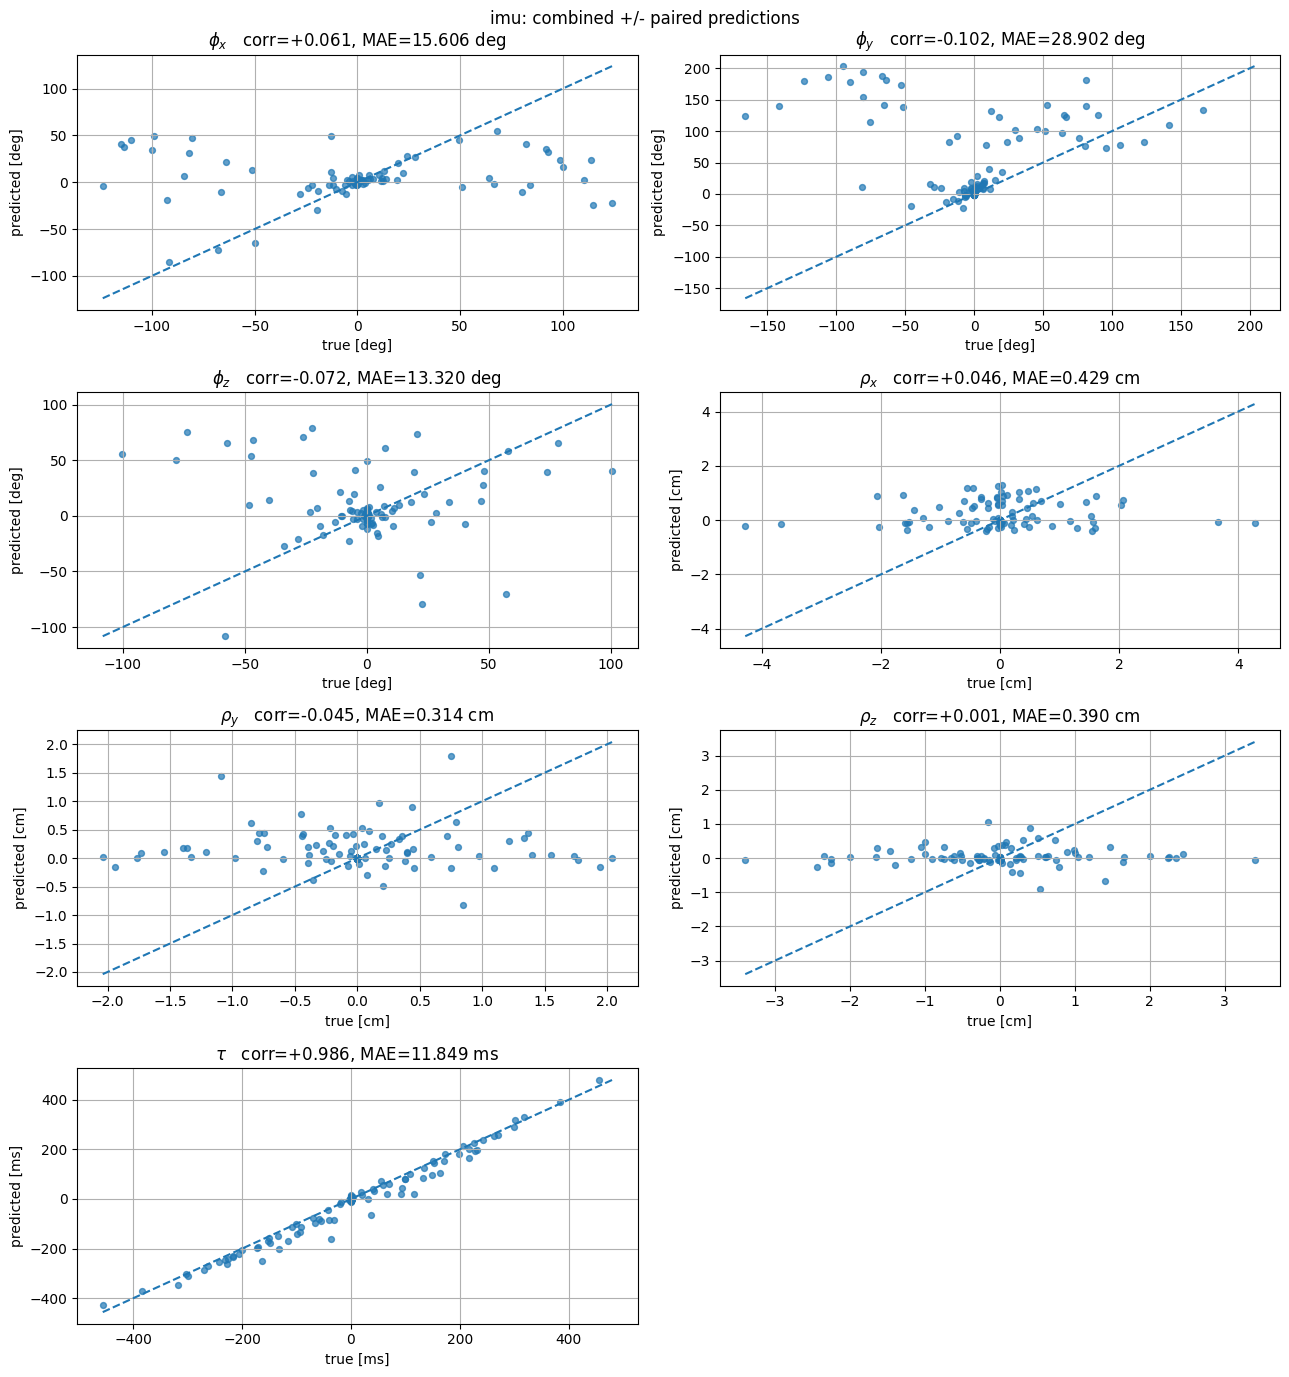

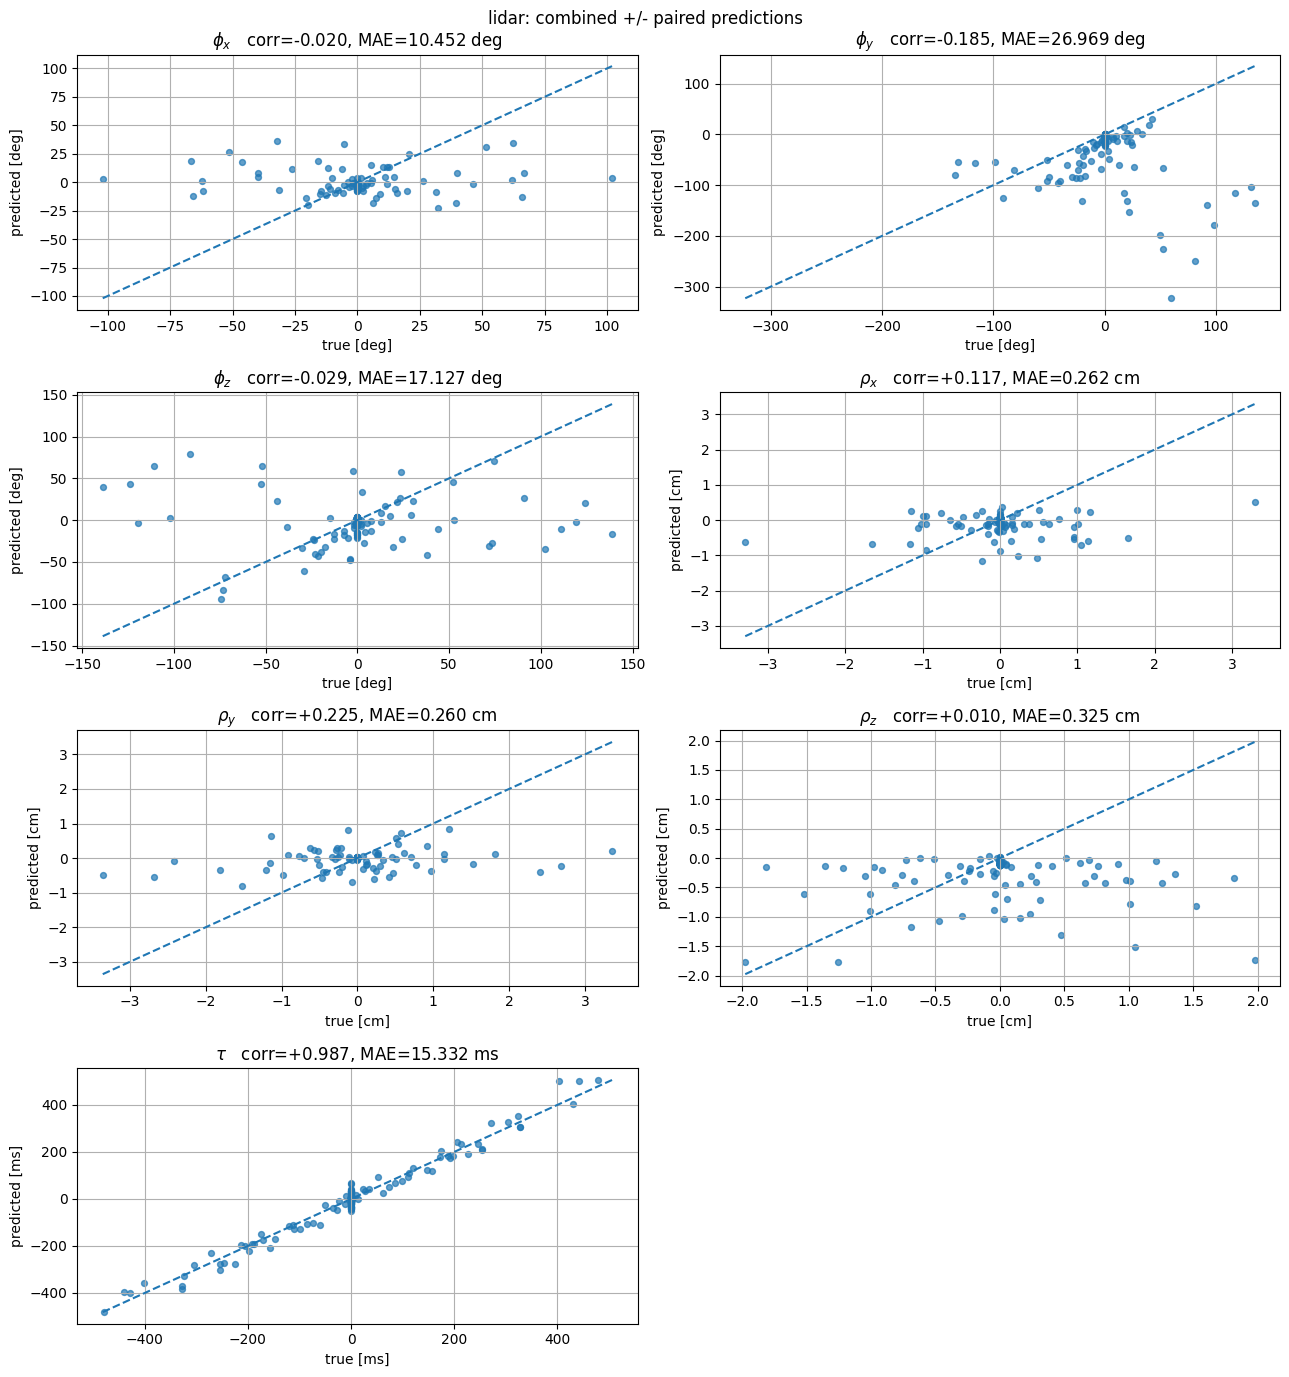

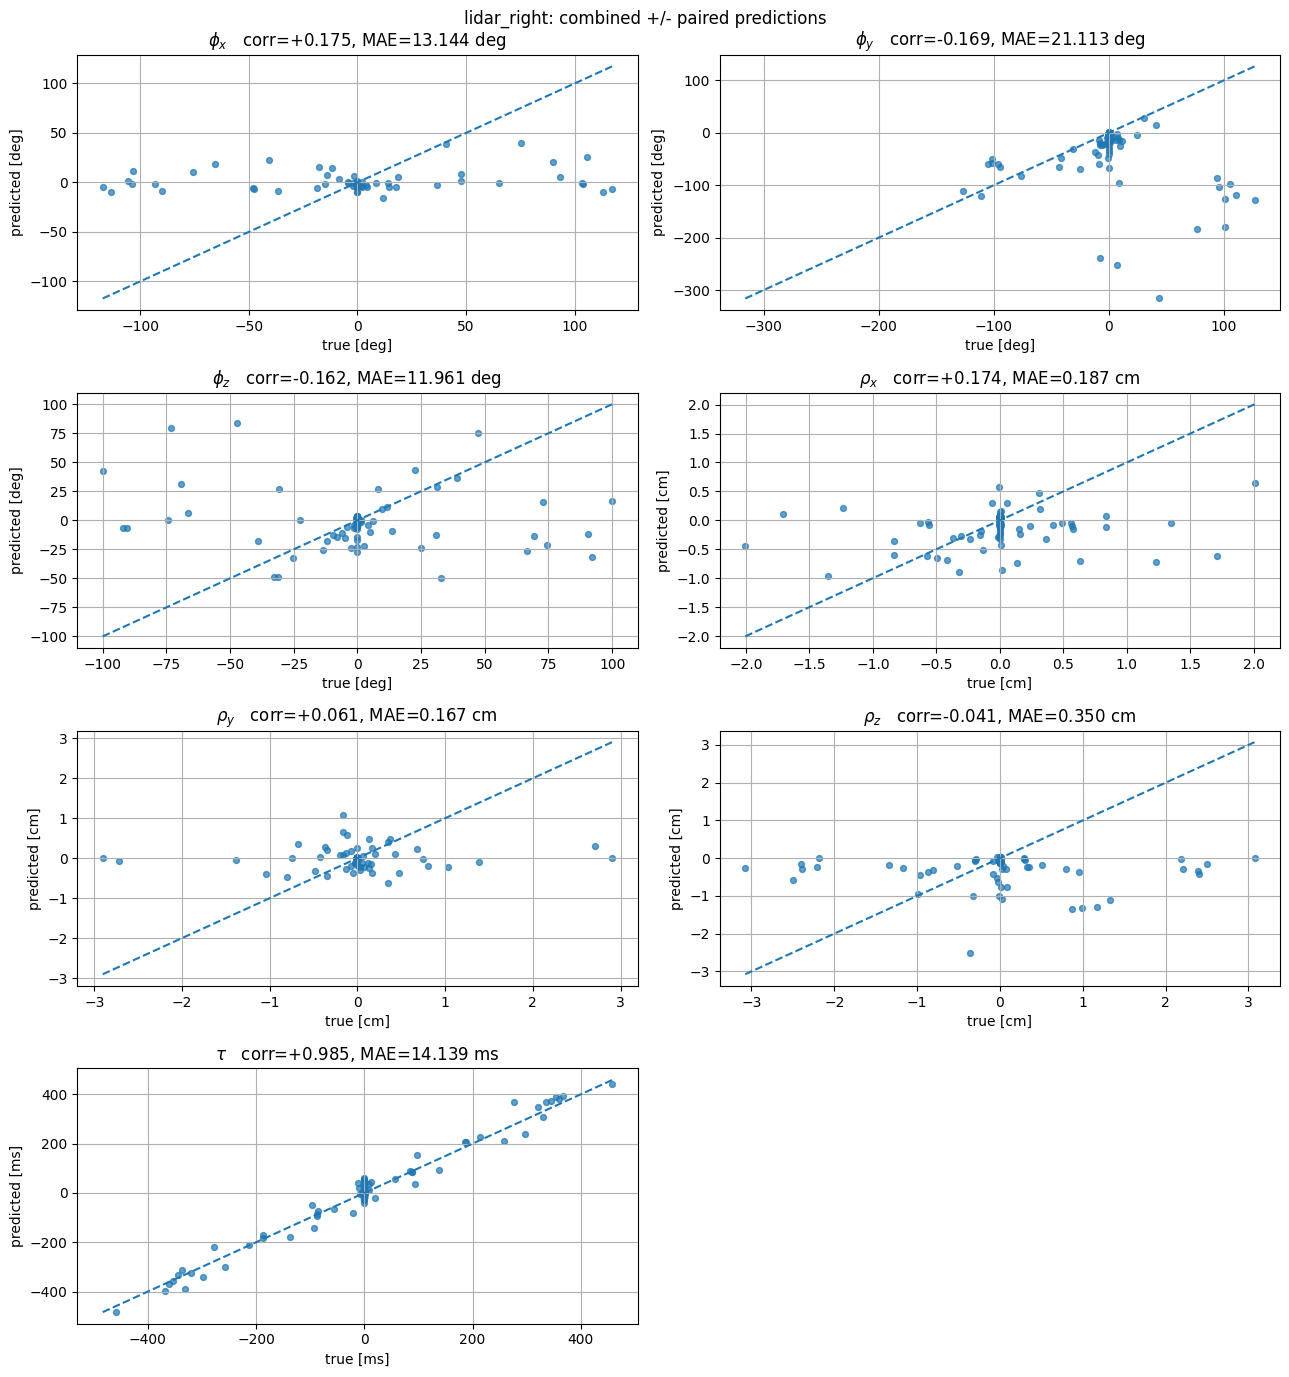

In [53]:
def plot_combined_true_vs_predicted_scatter(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    truth = np.concatenate([positive_true, negative_true], axis=0)
    prediction = np.concatenate([positive_predicted, negative_predicted], axis=0)

    component_names = (r"$\phi_x$", r"$\phi_y$", r"$\phi_z$", r"$\rho_x$", r"$\rho_y$", r"$\rho_z$", r"$\tau$")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")

    fig, axes = plt.subplots(4, 2, figsize=(13, 14))
    axes = axes.ravel()

    for component_index in range(7):
        ax = axes[component_index]
        component_truth = truth[:, component_index]
        component_prediction = prediction[:, component_index]

        minimum = min(component_truth.min(), component_prediction.min())
        maximum = max(component_truth.max(), component_prediction.max())
        correlation = np.corrcoef(component_truth, component_prediction)[0, 1] if np.std(component_truth) > 0.0 and np.std(component_prediction) > 0.0 else np.nan
        mae = np.mean(np.abs(component_prediction - component_truth))

        ax.scatter(component_truth, component_prediction, s=18, alpha=0.7)
        ax.plot([minimum, maximum], [minimum, maximum], linestyle="--")
        ax.set_xlabel(f"true [{units[component_index]}]")
        ax.set_ylabel(f"predicted [{units[component_index]}]")
        ax.set_title(f"{component_names[component_index]}   corr={correlation:+.3f}, MAE={mae:.3f} {units[component_index]}")
        ax.grid(True)

    axes[7].axis("off")
    fig.suptitle(f"{calibration_key}: combined +/- paired predictions")
    fig.tight_layout()
    plt.show()


for calibration_key in CALIBRATION_KEYS:
    plot_combined_true_vs_predicted_scatter(visualization_results, calibration_key)


## 24. Pair-difference scatter

This is the most important anti-collapse visualization. A constant predictor produces approximately zero pair difference and therefore a horizontal cloud. A useful paired model should approach the identity diagonal.


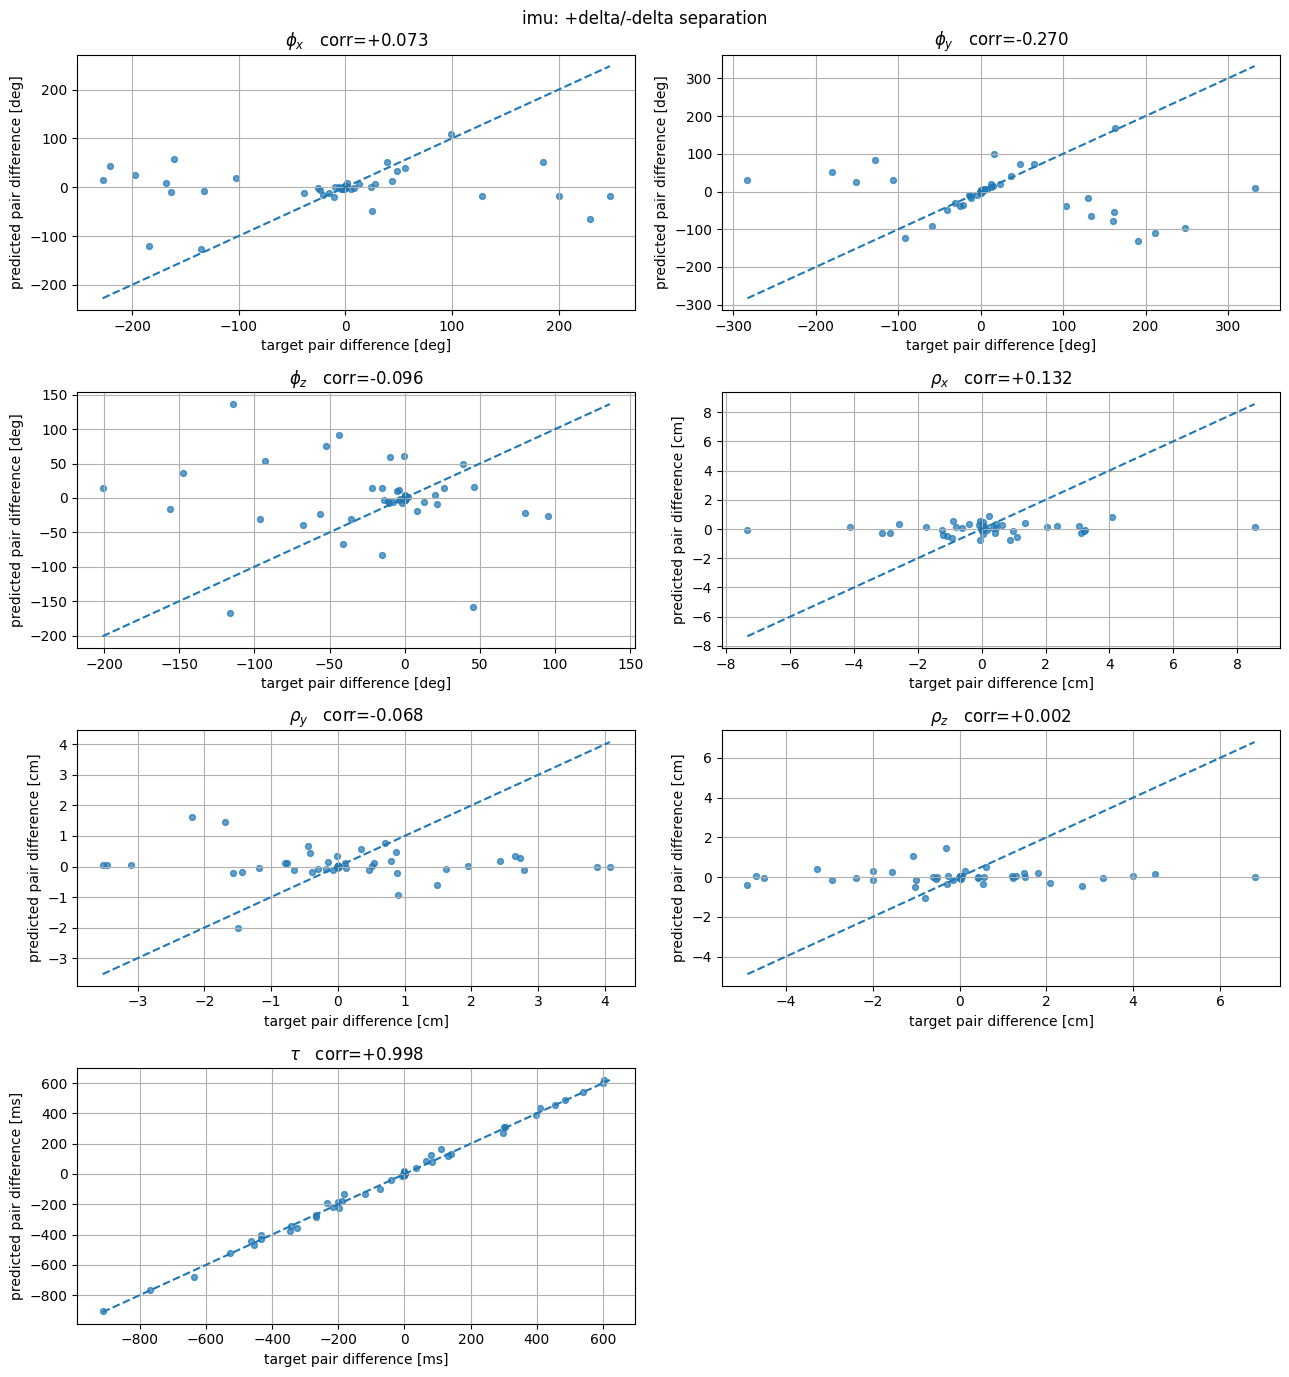

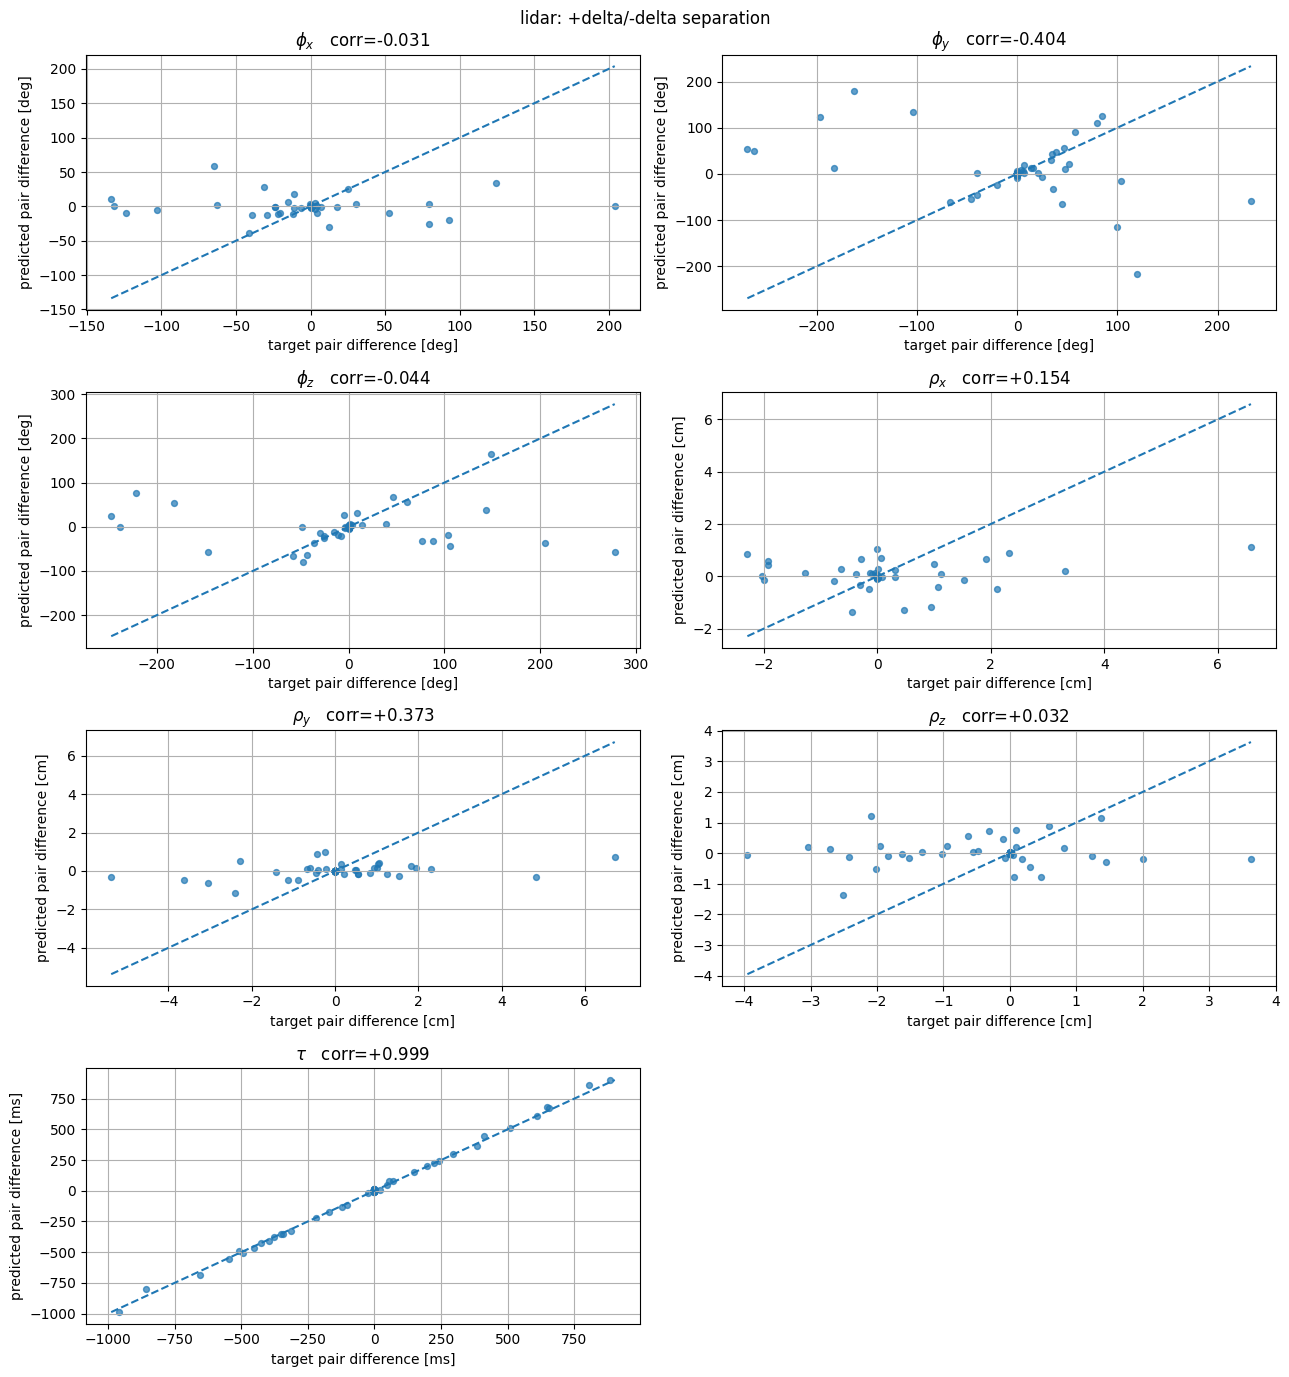

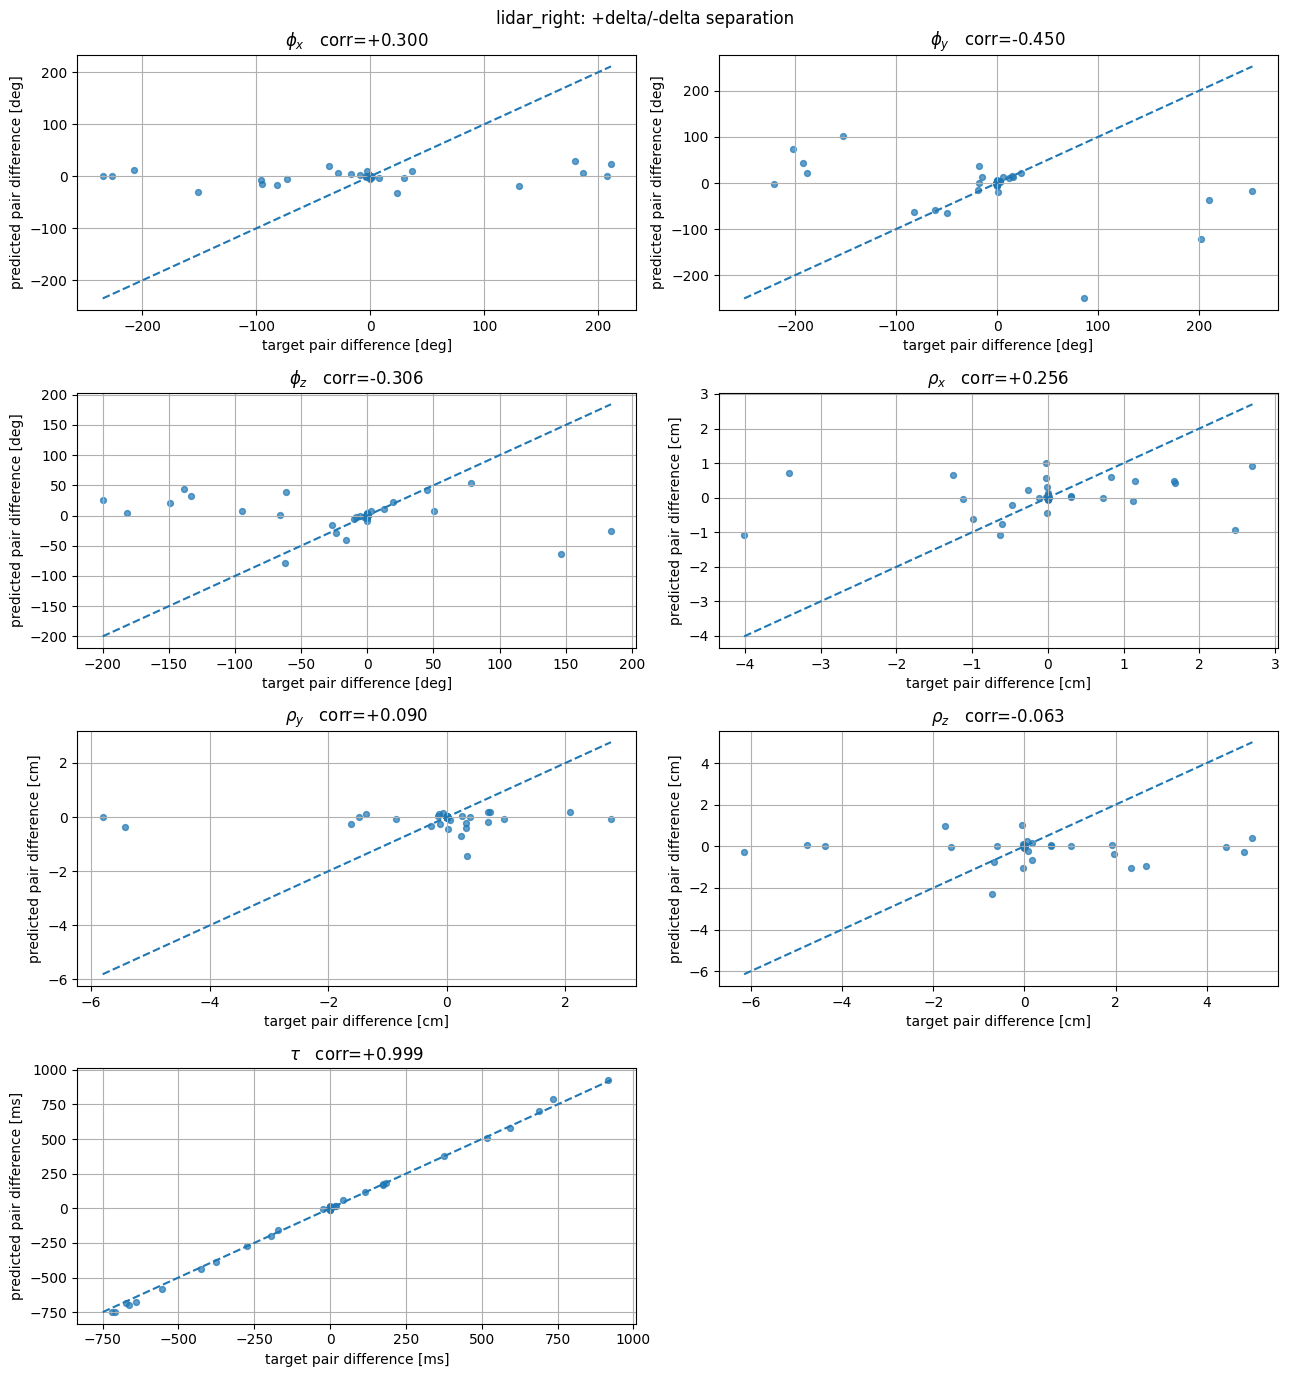

In [54]:
def plot_pair_difference_scatter(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    target_difference = positive_true - negative_true
    predicted_difference = positive_predicted - negative_predicted

    component_names = (r"$\phi_x$", r"$\phi_y$", r"$\phi_z$", r"$\rho_x$", r"$\rho_y$", r"$\rho_z$", r"$\tau$")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")

    fig, axes = plt.subplots(4, 2, figsize=(13, 14))
    axes = axes.ravel()

    for component_index in range(7):
        ax = axes[component_index]
        truth = target_difference[:, component_index]
        prediction = predicted_difference[:, component_index]

        minimum = min(truth.min(), prediction.min())
        maximum = max(truth.max(), prediction.max())
        correlation = np.corrcoef(truth, prediction)[0, 1] if np.std(truth) > 0.0 and np.std(prediction) > 0.0 else np.nan

        ax.scatter(truth, prediction, s=18, alpha=0.7)
        ax.plot([minimum, maximum], [minimum, maximum], linestyle="--")
        ax.set_xlabel(f"target pair difference [{units[component_index]}]")
        ax.set_ylabel(f"predicted pair difference [{units[component_index]}]")
        ax.set_title(f"{component_names[component_index]}   corr={correlation:+.3f}")
        ax.grid(True)

    axes[7].axis("off")
    fig.suptitle(f"{calibration_key}: +delta/-delta separation")
    fig.tight_layout()
    plt.show()


for calibration_key in CALIBRATION_KEYS:
    plot_pair_difference_scatter(visualization_results, calibration_key)


## 25. Numerical paired-prediction summary


In [55]:
def print_paired_prediction_summary(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    truth = np.concatenate([positive_true, negative_true], axis=0)
    prediction = np.concatenate([positive_predicted, negative_predicted], axis=0)
    target_difference = positive_true - negative_true
    predicted_difference = positive_predicted - negative_predicted

    component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")

    print(calibration_key)
    print(f"{'component':8s} {'MAE':>12s} {'corr':>10s} {'pred std':>12s} {'pair corr':>12s} {'pair MAE':>12s}")

    for component_index, component_name in enumerate(component_names):
        component_truth = truth[:, component_index]
        component_prediction = prediction[:, component_index]
        difference_truth = target_difference[:, component_index]
        difference_prediction = predicted_difference[:, component_index]

        mae = np.mean(np.abs(component_prediction - component_truth))
        correlation = np.corrcoef(component_truth, component_prediction)[0, 1] if np.std(component_truth) > 0.0 and np.std(component_prediction) > 0.0 else np.nan
        pair_correlation = np.corrcoef(difference_truth, difference_prediction)[0, 1] if np.std(difference_truth) > 0.0 and np.std(difference_prediction) > 0.0 else np.nan
        pair_mae = np.mean(np.abs(difference_prediction - difference_truth))

        print(
            f"{component_name:8s} "
            f"{mae:9.4f} {units[component_index]:3s} "
            f"{correlation:+10.4f} "
            f"{np.std(component_prediction):12.4f} "
            f"{pair_correlation:+12.4f} "
            f"{pair_mae:9.4f} {units[component_index]:3s}"
        )

    print()


for calibration_key in CALIBRATION_KEYS:
    print_paired_prediction_summary(visualization_results, calibration_key)


imu
component          MAE       corr     pred std    pair corr     pair MAE
phi_x      15.6057 deg    +0.0614      15.4164      +0.0732   30.3626 deg
phi_y      28.9024 deg    -0.1016      52.0967      -0.2700   36.4730 deg
phi_z      13.3196 deg    -0.0717      21.5325      -0.0961   23.6276 deg
rho_x       0.4294 cm     +0.0458       0.3519      +0.1319    0.6897 cm 
rho_y       0.3137 cm     -0.0448       0.2501      -0.0682    0.5679 cm 
rho_z       0.3905 cm     +0.0013       0.1824      +0.0018    0.7137 cm 
tau        11.8493 ms     +0.9862     122.7412      +0.9983    8.5480 ms 

lidar
component          MAE       corr     pred std    pair corr     pair MAE
phi_x      10.4521 deg    -0.0197       8.0071      -0.0306   17.2065 deg
phi_y      26.9688 deg    -0.1855      48.3401      -0.4044   32.8222 deg
phi_z      17.1265 deg    -0.0292      20.9564      -0.0440   26.8240 deg
rho_x       0.2616 cm     +0.1168       0.2368      +0.1535    0.4388 cm 
rho_y       0.2597 cm     +0.

## 26. Exact-truth fixed-point diagnostic


In [56]:
FIXED_POINT_NUM_WINDOWS = min(100, len(sequence_indices))
fixed_point_positions = np.unique(np.linspace(0, len(sequence_indices) - 1, FIXED_POINT_NUM_WINDOWS).round().astype(int))
fixed_point_indices = np.asarray(sequence_indices)[fixed_point_positions]

fixed_point_results = {calibration_key: {"delta_xi": [], "delta_tau": []} for calibration_key in CALIBRATION_KEYS}

model.eval()

with torch.no_grad():
    for dataset_index in fixed_point_indices:
        window = window_batch_to(collate_windows([test_dataset[int(dataset_index)]]), DEVICE, dtype=MODEL_DTYPE)
        exact_true_calibration = {calibration_key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for calibration_key, state in window.current_calibration.items()}
        result = window_step(window, calibration=exact_true_calibration)

        for calibration_key, prediction in result.model_output.predictions.items():
            fixed_point_results[calibration_key]["delta_xi"].append(prediction.delta_xi[0].detach().cpu())
            fixed_point_results[calibration_key]["delta_tau"].append(prediction.delta_tau[0, 0].detach().cpu())

for calibration_key in CALIBRATION_KEYS:
    fixed_point_results[calibration_key]["delta_xi"] = torch.stack(fixed_point_results[calibration_key]["delta_xi"]).numpy()
    fixed_point_results[calibration_key]["delta_tau"] = torch.stack(fixed_point_results[calibration_key]["delta_tau"]).numpy()

component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")

print("=" * 120)
print("EXACT-TRUTH FIXED-POINT DIAGNOSTIC")
print("=" * 120)

for calibration_key in CALIBRATION_KEYS:
    result = fixed_point_results[calibration_key]
    prediction = np.concatenate([result["delta_xi"], result["delta_tau"][:, None]], axis=1)

    print(calibration_key)
    print(f"{'component':8s} {'mean':>16s} {'mean |x|':>16s} {'RMSE':>16s} {'std':>16s} {'range':>16s}")

    for component_index, component_name in enumerate(component_names):
        values = prediction[:, component_index]

        if component_index < 3:
            values, unit = np.rad2deg(values), "deg"
        elif component_index < 6:
            values, unit = 100.0 * values, "cm"
        else:
            values, unit = 1000.0 * values, "ms"

        mean = np.mean(values)
        mean_abs = np.mean(np.abs(values))
        rmse = np.sqrt(np.mean(values ** 2))
        std = np.std(values)
        value_range = np.max(values) - np.min(values)

        print(f"{component_name:8s} {mean:+12.6f} {unit:3s} {mean_abs:12.6f} {unit:3s} {rmse:12.6f} {unit:3s} {std:12.6f} {unit:3s} {value_range:12.6f} {unit:3s}")

    print()


/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


EXACT-TRUTH FIXED-POINT DIAGNOSTIC
imu
component             mean         mean |x|             RMSE              std            range
phi_x       +0.721044 deg     1.332531 deg     1.609823 deg     1.439315 deg     7.954638 deg
phi_y       +0.635726 deg     1.180155 deg     1.487350 deg     1.344641 deg     6.399630 deg
phi_z       +0.362761 deg     2.143080 deg     2.760265 deg     2.736324 deg    16.596447 deg
rho_x       -0.092608 cm      0.092608 cm      0.097960 cm      0.031937 cm      0.181753 cm 
rho_y       -0.002334 cm      0.003997 cm      0.004956 cm      0.004372 cm      0.031287 cm 
rho_z       +0.000575 cm      0.010771 cm      0.016105 cm      0.016095 cm      0.108108 cm 
tau         +0.484466 ms      4.509427 ms      6.440342 ms      6.422094 ms     42.466866 ms 

lidar
component             mean         mean |x|             RMSE              std            range
phi_x       -1.595364 deg     1.770476 deg     2.506913 deg     1.933760 deg    11.620979 deg
phi_y       

## 27. Interpretation gate

This is a scratch test of the original **3D-output paired model** on *both* fine and coarse arbitrary-axis faults, with KAIST three-sensor reference offsets corrected. Read the fixed fine/coarse stochastic curves separately and monitor held-out SO(3) error. The paired group-relative loss avoids equating physically close +179°/−179° corrections with rotation vectors 358° apart. For checkpoint selection, the original full loop continues to use validation loss; if near-π performance is important, evaluate a fixed angle-stratified probe bank before declaring success.


# Shuffle diagnostics of prior-only training

In [57]:
# Measurement-shuffle diagnostic.
# Keep every calibration prior and supervision target attached to its original batch item,
# but replace the complete measurement window by another item's measurement window.
# If performance barely changes, the model can solve the task mostly from calibration context alone.
# If performance degrades substantially, the model is genuinely using the sensor measurements.

from obscalib.data.structures import SensorStreamBatch, WindowBatch

MEASUREMENT_SHUFFLE_NUM_WINDOWS = min(BATCH_SIZE, 16)
MEASUREMENT_SHUFFLE_PAIR_SEED = TEST_PAIR_SEED + 700000
MEASUREMENT_SHUFFLE_PERMUTATION_SEED = TEST_PAIR_SEED + 800000

measurement_shuffle_indices = np.linspace(0, len(test_dataset) - 1, MEASUREMENT_SHUFFLE_NUM_WINDOWS, dtype=int)
measurement_shuffle_base_window = collate_windows([test_dataset[int(index)] for index in measurement_shuffle_indices])
measurement_shuffle_base_window = window_batch_to(measurement_shuffle_base_window, DEVICE, dtype=MODEL_DTYPE)

measurement_shuffle_pair_generator = make_augmentation_generator(MEASUREMENT_SHUFFLE_PAIR_SEED)

measurement_shuffle_positive_window, measurement_shuffle_negative_window, _, _ = make_paired_windows(
    measurement_shuffle_base_window,
    generator=measurement_shuffle_pair_generator,
)

batch_size = next(iter(measurement_shuffle_positive_window.streams.values())).values.shape[0]

if batch_size < 2:
    raise ValueError("Measurement-shuffle diagnostic requires at least two batch items.")

# Build a deterministic random derangement so no batch item keeps its own measurements.
permutation_rng = np.random.default_rng(MEASUREMENT_SHUFFLE_PERMUTATION_SEED)
identity_permutation = np.arange(batch_size)

while True:
    measurement_permutation_numpy = permutation_rng.permutation(batch_size)

    if np.all(measurement_permutation_numpy != identity_permutation):
        break

measurement_permutation = torch.as_tensor(measurement_permutation_numpy, dtype=torch.long)


def shuffle_window_measurements(window: WindowBatch, permutation: torch.Tensor) -> WindowBatch:
    shuffled_streams = {}

    for stream_key, stream in window.streams.items():
        stream_permutation = permutation.to(stream.values.device)

        shuffled_streams[stream_key] = SensorStreamBatch(
            values=stream.values[stream_permutation],
            timestamps=stream.timestamps[stream_permutation],
            sample_mask=stream.sample_mask[stream_permutation],
            interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps[stream_permutation],
        )

    return WindowBatch(
        streams=shuffled_streams,
        current_calibration=dict(window.current_calibration),
        metadata=dict(window.metadata),
        targets=None if window.targets is None else dict(window.targets),
        dataset_indices=window.dataset_indices,
    )


measurement_shuffle_positive_shuffled_window = shuffle_window_measurements(measurement_shuffle_positive_window, measurement_permutation)
measurement_shuffle_negative_shuffled_window = shuffle_window_measurements(measurement_shuffle_negative_window, measurement_permutation)


def evaluate_measurement_shuffle_pair(positive_window: WindowBatch, negative_window: WindowBatch):
    with torch.inference_mode():
        positive_result = window_step(positive_window)
        positive_output = positive_result.model_output
        del positive_result

        negative_result = window_step(negative_window)
        negative_output = negative_result.model_output
        del negative_result

        loss, metrics = compute_paired_objective(
            positive_window,
            positive_output,
            negative_window,
            negative_output,
        )

        prediction_summary = {}

        for calibration_key in CALIBRATION_KEYS:
            prediction_summary[calibration_key] = {
                "positive_xi": positive_output.predictions[calibration_key].delta_xi.detach().cpu(),
                "negative_xi": negative_output.predictions[calibration_key].delta_xi.detach().cpu(),
                "positive_tau": positive_output.predictions[calibration_key].delta_tau.detach().cpu(),
                "negative_tau": negative_output.predictions[calibration_key].delta_tau.detach().cpu(),
            }

        loss_value = float(loss.detach().cpu())
        metric_values = {key: float(value.detach().cpu()) if torch.is_tensor(value) else float(value) for key, value in metrics.items()}

        del positive_output
        del negative_output
        del loss

    return loss_value, metric_values, prediction_summary


previous_training_mode = model.training
model.eval()

try:
    normal_total, normal_metrics, normal_predictions = evaluate_measurement_shuffle_pair(
        measurement_shuffle_positive_window,
        measurement_shuffle_negative_window,
    )

    shuffled_total, shuffled_metrics, shuffled_predictions = evaluate_measurement_shuffle_pair(
        measurement_shuffle_positive_shuffled_window,
        measurement_shuffle_negative_shuffled_window,
    )

finally:
    model.train(previous_training_mode)


print("=" * 110)
print("MEASUREMENT-SHUFFLE DEPENDENCE DIAGNOSTIC")
print("=" * 110)
print("windows:", batch_size)
print("measurement permutation:", measurement_permutation_numpy.tolist())
print()
print("Calibration priors: unchanged")
print("Supervision targets: unchanged")
print("Measurements: complete physical windows reassigned between batch items")
print()
print(f"{'condition':14s} {'total':>12s} {'regular':>12s} {'pair':>12s}")
print(f"{'normal':14s} {normal_total:12.6f} {normal_metrics['loss_regular']:12.6f} {normal_metrics['loss_pair']:12.6f}")
print(f"{'shuffled':14s} {shuffled_total:12.6f} {shuffled_metrics['loss_regular']:12.6f} {shuffled_metrics['loss_pair']:12.6f}")
print()

total_ratio = shuffled_total / max(normal_total, 1e-12)
regular_ratio = shuffled_metrics["loss_regular"] / max(normal_metrics["loss_regular"], 1e-12)
pair_ratio = shuffled_metrics["loss_pair"] / max(normal_metrics["loss_pair"], 1e-12)

print(f"shuffled / normal total loss:   {total_ratio:.3f}x")
print(f"shuffled / normal regular loss: {regular_ratio:.3f}x")
print(f"shuffled / normal pair loss:    {pair_ratio:.3f}x")
print()

for calibration_key in CALIBRATION_KEYS:
    normal = normal_predictions[calibration_key]
    shuffled = shuffled_predictions[calibration_key]

    positive_xi_change = torch.linalg.vector_norm(shuffled["positive_xi"] - normal["positive_xi"], dim=-1).mean().item()
    negative_xi_change = torch.linalg.vector_norm(shuffled["negative_xi"] - normal["negative_xi"], dim=-1).mean().item()
    positive_tau_change = torch.abs(shuffled["positive_tau"] - normal["positive_tau"]).mean().item()
    negative_tau_change = torch.abs(shuffled["negative_tau"] - normal["negative_tau"]).mean().item()

    print(calibration_key)
    print(f"  mean prediction change after measurement shuffle, + branch: xi={positive_xi_change:.6e}, tau={positive_tau_change:.6e}")
    print(f"  mean prediction change after measurement shuffle, - branch: xi={negative_xi_change:.6e}, tau={negative_tau_change:.6e}")
    print()

print("Interpretation:")
print("  Large loss increase and/or large prediction changes -> the model uses measurement content.")
print("  Nearly unchanged losses and predictions             -> the model is relying mostly on calibration context.")

del measurement_shuffle_base_window
del measurement_shuffle_positive_window
del measurement_shuffle_negative_window
del measurement_shuffle_positive_shuffled_window
del measurement_shuffle_negative_shuffled_window
del normal_predictions
del shuffled_predictions

torch.cuda.empty_cache()

MEASUREMENT-SHUFFLE DEPENDENCE DIAGNOSTIC
windows: 16
measurement permutation: [4, 0, 10, 12, 9, 13, 5, 3, 6, 15, 14, 7, 11, 1, 8, 2]

Calibration priors: unchanged
Supervision targets: unchanged
Measurements: complete physical windows reassigned between batch items

condition             total      regular         pair
normal             5.596265     1.143760     0.445250
shuffled         203.969376     9.481003    19.448837

shuffled / normal total loss:   36.447x
shuffled / normal regular loss: 8.289x
shuffled / normal pair loss:    43.681x

imu
  mean prediction change after measurement shuffle, + branch: xi=1.477255e+00, tau=6.164543e-02
  mean prediction change after measurement shuffle, - branch: xi=1.737853e+00, tau=7.490116e-02

lidar
  mean prediction change after measurement shuffle, + branch: xi=8.589860e-01, tau=1.190701e-01
  mean prediction change after measurement shuffle, - branch: xi=8.353829e-01, tau=8.369069e-02

lidar_right
  mean prediction change after measuremen

## 25A. Exact-angle and feedback SO(3) diagnostics
These cells evaluate physical rotation corrections on held-out KAIST validation windows, not merely component-wise scatter plots. They leave model/optimizer weights unchanged. They evaluate the currently loaded model (after the existing Cell 51 loads best.pt, if it exists). The stochastic test in Cell 32 restores its pre-test weights, so its temporary 1000-step learner is not what these later cells evaluate. Set the desired trained checkpoint before running these cells.

In [58]:
# Notebook 65, additional SO(3) diagnostics: add after the paired-prediction summary (old Cell 59).
# All diagnostic rotations are exact-angle faults; measurements and true calibration are kept fixed.
import pandas as pd
from obscalib.geometry.lie import se3_exp, so3_exp

DIAG65_ANGLES_DEG = (0.0, 15.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
DIAG65_FAULT_KEYS = CALIBRATION_KEYS
DIAG65_NUM_PHYSICAL_WINDOWS = 8
DIAG65_PHYSICAL_SEED = 650_271
DIAG65_AXIS_SEED = 650_272
DIAG65_AXIS_NAMES = ('X', 'Y', 'Z', 'U1', 'U2')
DIAG65_OUTPUT_DIR = RUN_DIR / 'plots' / 'so3_correction_diagnostics'
DIAG65_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Defaults for the more expensive chronological-feedback experiment.
ROLL65_SEQUENCES = (VAL_NAMES[0],)              # Can increase to tuple(VAL_NAMES).
ROLL65_STARTS_PER_SEQUENCE = 1
ROLL65_NUM_WINDOWS = 12                         # Consecutive 5-second windows.
ROLL65_FAULT_KEYS = ('lidar', 'lidar_right', 'imu')
ROLL65_AXIS_NAMES = ('U1',)                    # Add 'X', 'Y', 'Z', 'U2' to diagnose axis dependence.
ROLL65_ANGLES_DEG = (0.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
ROLL65_UPDATE_MODE = 'rotation_only'            # Or 'full_se3' to update translation and tau as well.
ROLL65_UPDATE_ALL_KEYS = False                  # True lets predictions change healthy sensors too.
ROLL65_PHYSICAL_SEED = 650_273

if not set(DIAG65_FAULT_KEYS).issubset(CALIBRATION_KEYS) or not set(ROLL65_FAULT_KEYS).issubset(CALIBRATION_KEYS):
    raise ValueError('Unknown calibration key in diagnostics')
if ROLL65_UPDATE_MODE not in ('rotation_only', 'full_se3'):
    raise ValueError(f'Invalid ROLL65_UPDATE_MODE: {ROLL65_UPDATE_MODE}')


def diag65_rotation_distance_deg(R_a, R_b):
    """Stable SO(3) geodesic distance in degrees, including close to 0 and pi."""
    R = R_a @ R_b.transpose(-1, -2)
    skew = torch.stack((R[..., 2, 1] - R[..., 1, 2], R[..., 0, 2] - R[..., 2, 0], R[..., 1, 0] - R[..., 0, 1]), dim=-1)
    sin_theta = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cos_theta = 0.5 * (R.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0)
    return torch.rad2deg(torch.atan2(sin_theta, cos_theta))


def diag65_copy_states(states):
    return {key: CalibrationState(transform=state.transform.detach().clone(), time_offset=state.time_offset.detach().clone()) for key, state in states.items()}


def diag65_make_axes():
    axes = {
        'X': torch.tensor([1.0, 0.0, 0.0], device=DEVICE, dtype=MODEL_DTYPE),
        'Y': torch.tensor([0.0, 1.0, 0.0], device=DEVICE, dtype=MODEL_DTYPE),
        'Z': torch.tensor([0.0, 0.0, 1.0], device=DEVICE, dtype=MODEL_DTYPE),
    }
    generator = make_augmentation_generator(DIAG65_AXIS_SEED)
    for name in ('U1', 'U2'):
        direction = torch.randn(3, generator=generator, device=DEVICE, dtype=MODEL_DTYPE)
        axes[name] = direction / direction.norm().clamp_min(1e-12)
    return axes


DIAG65_AXES = diag65_make_axes()
for axis_name in DIAG65_AXIS_NAMES:
    print(f'{axis_name}: {DIAG65_AXES[axis_name].detach().cpu().numpy().round(4)}')
print('Model evaluated: the model currently in memory (Cell 51 loads best.pt when it exists).')
print('Rollout mode:', ROLL65_UPDATE_MODE, '| update healthy sensors:', ROLL65_UPDATE_ALL_KEYS)


X: [1. 0. 0.]
Y: [0. 1. 0.]
Z: [0. 0. 1.]
U1: [ 0.0396  0.5705 -0.8203]
U2: [-0.5292 -0.6864 -0.4988]
Model evaluated: the model currently in memory (Cell 51 loads best.pt when it exists).
Rollout mode: rotation_only | update healthy sensors: False


## 25B. Exact-angle one-step SO(3) correction evaluation
Produces remaining error vs initial fault, predicted correction magnitude, axis cosine and percentage of examples improved. Uses only pure rotation faults, so translation and timing errors do not confound this specific test.

One-step SO(3) errors on validation physical windows; positive gain means improvement.
        key  angle_deg  residual_deg  gain_deg  predicted_deg  improved_pct  n
        imu        0.0          2.02     -2.02           2.02          0.00 40
        imu       15.0          9.13      5.87           9.96         87.50 80
        imu       30.0         20.20      9.80          26.94         78.75 80
        imu       60.0         60.98     -0.98          73.75         58.75 80
        imu       90.0         89.87      0.13          86.71         47.50 80
        imu      120.0        104.74     15.26         107.57         51.25 80
        imu      150.0        113.18     36.82         116.03         60.00 80
        imu      175.0        115.77     59.23         117.76         67.50 80
        imu      179.0        116.04     62.96         117.75         87.50 80
      lidar        0.0          7.20     -7.20           7.20          0.00 40
      lidar       15.0         16.03     -1.

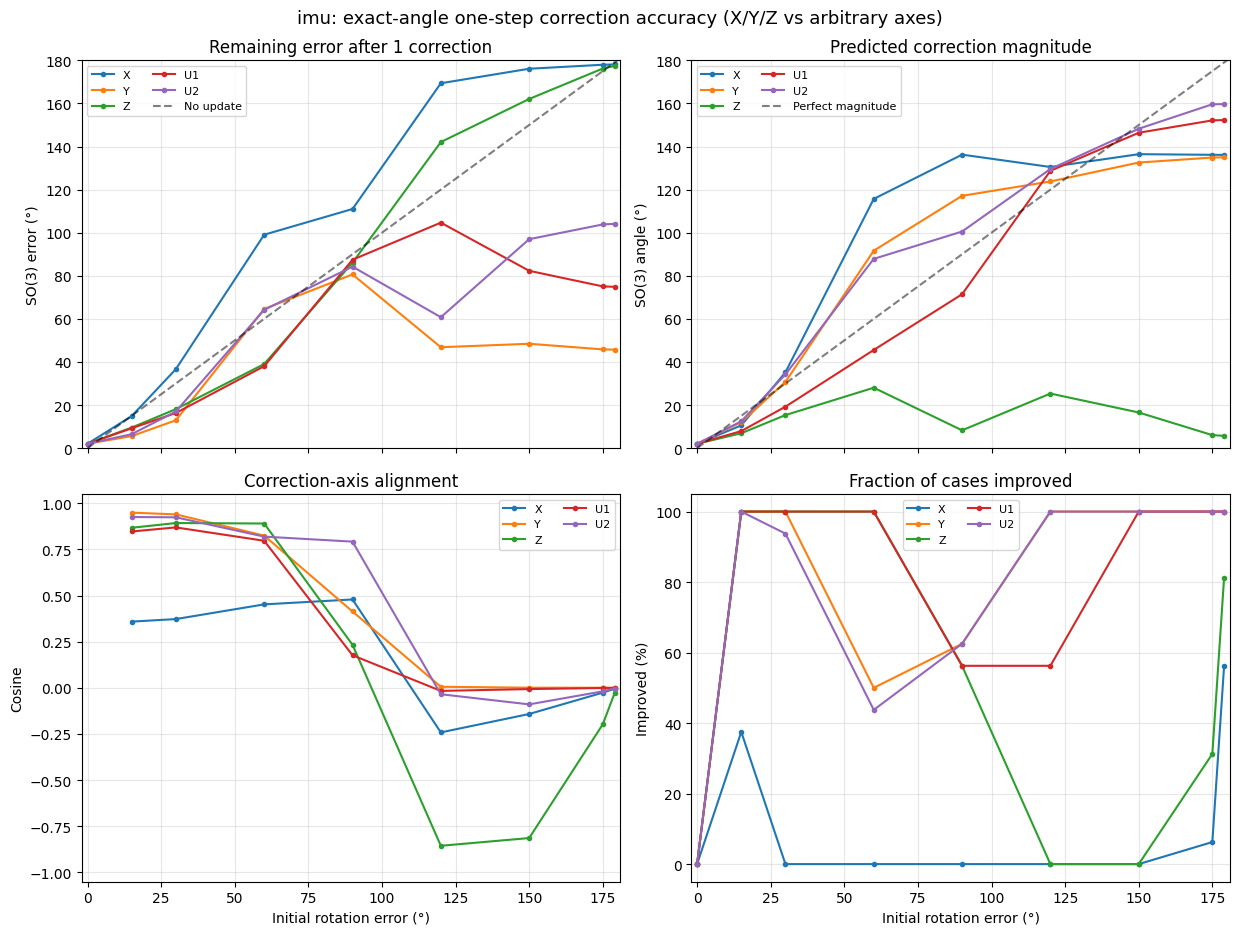

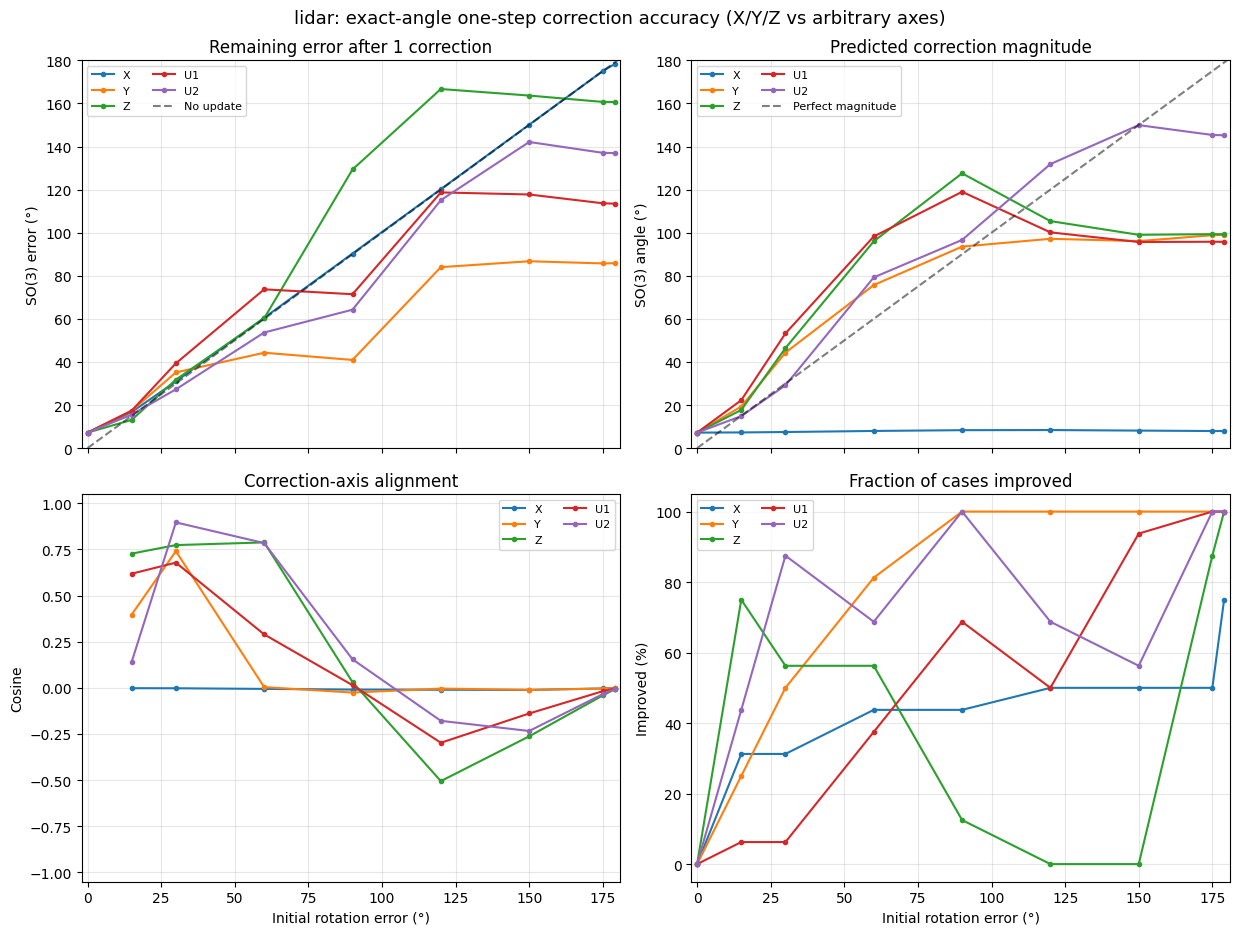

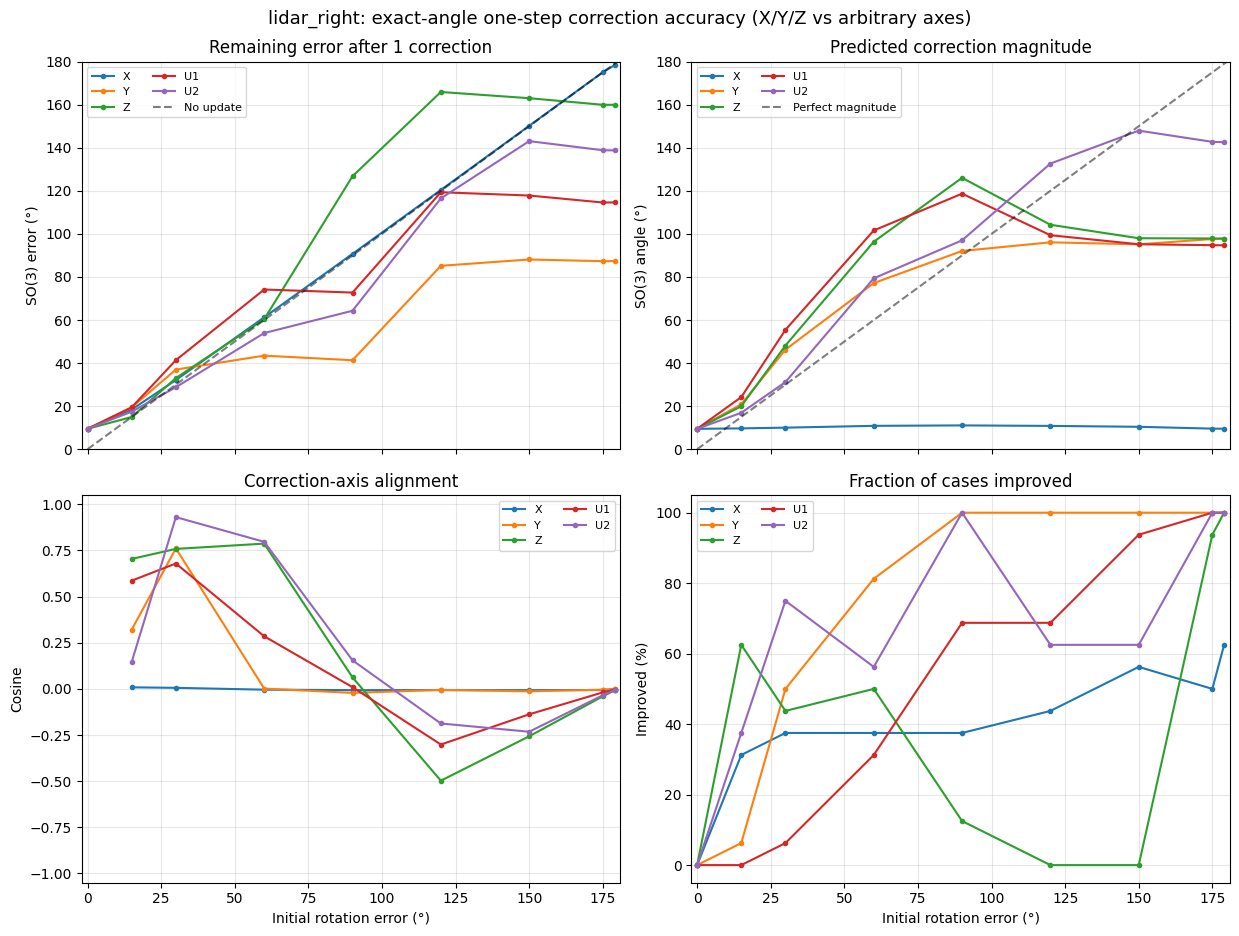

Saved one-step cases, summaries and figures under: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_large_paired_003.3_3d_large/plots/so3_correction_diagnostics


In [59]:
# Exact-angle one-step corrections on held-out physical windows. No checkpoint or weights are modified.
@torch.inference_mode()
def diag65_run_one_step():
    indices = np.asarray(val_dataset.window_indices_for_sequence(VAL_NAMES[0]), dtype=int)
    chosen = indices[np.unique(np.linspace(0, len(indices) - 1, min(DIAG65_NUM_PHYSICAL_WINDOWS, len(indices))).round().astype(int))]
    base_window = window_batch_to(collate_windows([val_dataset[int(i)] for i in chosen]), DEVICE, dtype=MODEL_DTYPE)
    physical = context_augmentation_pipeline(base_window, generator=make_augmentation_generator(DIAG65_PHYSICAL_SEED)).augmented_window
    truth = physical.current_calibration
    batch_size = len(chosen)
    rows = []
    was_training = model.training
    model.eval()
    try:
        for key in DIAG65_FAULT_KEYS:
            for axis_name in DIAG65_AXIS_NAMES:
                axis = DIAG65_AXES[axis_name]
                for angle in DIAG65_ANGLES_DEG:
                    for sign in ((1,) if angle == 0.0 else (-1, 1)):
                        xi = {name: torch.zeros(batch_size, 6, device=DEVICE, dtype=MODEL_DTYPE) for name in CALIBRATION_KEYS}
                        tau = {name: torch.zeros(batch_size, 1, device=DEVICE, dtype=MODEL_DTYPE) for name in CALIBRATION_KEYS}
                        xi[key][:, :3] = sign * np.deg2rad(angle) * axis
                        prior = apply_prior_perturbation(truth, xi, tau)
                        probe_window = clone_window_with_calibration(physical, prior)
                        prediction = window_step(probe_window).model_output.predictions[key]
                        predicted_phi = prediction.delta_xi[:, :3]
                        true_xi, _ = correction_target(probe_window, key)
                        true_phi = true_xi[:, :3]
                        R_prior = prior[key].transform[:, :3, :3]
                        R_truth = truth[key].transform[:, :3, :3]
                        R_after = so3_exp(predicted_phi) @ R_prior   # Left-composed rotation update, as in calibration targets.
                        initial = diag65_rotation_distance_deg(R_prior, R_truth)
                        residual = diag65_rotation_distance_deg(R_after, R_truth)
                        R_predicted = so3_exp(predicted_phi)
                        R_identity = torch.eye(3, device=DEVICE, dtype=MODEL_DTYPE).expand_as(R_predicted)
                        predicted_angle = diag65_rotation_distance_deg(R_predicted, R_identity)
                        cos_axis = F.cosine_similarity(predicted_phi, true_phi, dim=-1)
                        cos_axis = torch.where((predicted_phi.norm(dim=-1) > np.deg2rad(1.0)) & (true_phi.norm(dim=-1) > np.deg2rad(1.0)), cos_axis, torch.nan)
                        if not torch.isfinite(residual).all() or (initial - angle).abs().max() > 0.25:
                            raise RuntimeError(f'Invalid exact-angle probe, key={key} axis={axis_name} angle={angle}°')
                        for j in range(batch_size):
                            before, after = float(initial[j]), float(residual[j])
                            rows.append(dict(key=key, axis=axis_name, signed_angle_deg=float(sign * angle), initial_deg=before,
                                             angle_deg=float(angle), window_index=int(chosen[j]), residual_deg=after,
                                             gain_deg=before - after, predicted_deg=float(predicted_angle[j]),
                                             axis_cos=float(cos_axis[j]), improved=bool(after < before - 1e-4),
                                             success_10deg=bool(after < 10.0)))
    finally:
        model.train(was_training)
    return pd.DataFrame(rows)


diag65_one_df = diag65_run_one_step()
diag65_one_df.to_csv(DIAG65_OUTPUT_DIR / 'one_step_cases.csv', index=False)
diag65_one_summary = diag65_one_df.groupby(['key', 'axis', 'angle_deg'], as_index=False).agg(
    mean_residual_deg=('residual_deg', 'mean'), median_residual_deg=('residual_deg', 'median'),
    mean_predicted_deg=('predicted_deg', 'mean'), mean_gain_deg=('gain_deg', 'mean'),
    axis_cos=('axis_cos', 'mean'), improved_fraction=('improved', 'mean'),
    success_10deg=('success_10deg', 'mean'), n=('residual_deg', 'size'))
diag65_one_summary.to_csv(DIAG65_OUTPUT_DIR / 'one_step_summary.csv', index=False)

print('One-step SO(3) errors on validation physical windows; positive gain means improvement.')
print(diag65_one_df.groupby(['key', 'angle_deg'], as_index=False).agg(
    residual_deg=('residual_deg', 'mean'), gain_deg=('gain_deg', 'mean'), predicted_deg=('predicted_deg', 'mean'),
    improved_pct=('improved', lambda x: 100 * x.mean()), n=('residual_deg', 'size')).round(2).to_string(index=False))

for key in DIAG65_FAULT_KEYS:
    fig, axes = plt.subplots(2, 2, figsize=(12.5, 9.5), sharex=True)
    for axis_name in DIAG65_AXIS_NAMES:
        curve = diag65_one_summary[(diag65_one_summary.key == key) & (diag65_one_summary.axis == axis_name)].sort_values('angle_deg')
        x = curve.angle_deg
        axes[0, 0].plot(x, curve.mean_residual_deg, '-o', markersize=3, label=axis_name)
        axes[0, 1].plot(x, curve.mean_predicted_deg, '-o', markersize=3, label=axis_name)
        axes[1, 0].plot(x, curve.axis_cos, '-o', markersize=3, label=axis_name)
        axes[1, 1].plot(x, 100 * curve.improved_fraction, '-o', markersize=3, label=axis_name)
    axes[0, 0].plot([0, 180], [0, 180], 'k--', alpha=0.5, label='No update')
    axes[0, 1].plot([0, 180], [0, 180], 'k--', alpha=0.5, label='Perfect magnitude')
    axes[0, 0].set(title='Remaining error after 1 correction', ylabel='SO(3) error (°)', ylim=(0, 180))
    axes[0, 1].set(title='Predicted correction magnitude', ylabel='SO(3) angle (°)', ylim=(0, 180))
    axes[1, 0].set(title='Correction-axis alignment', xlabel='Initial rotation error (°)', ylabel='Cosine', ylim=(-1.05, 1.05))
    axes[1, 1].set(title='Fraction of cases improved', xlabel='Initial rotation error (°)', ylabel='Improved (%)', ylim=(-5, 105))
    for ax in axes.flat:
        ax.set_xlim(-2, 181)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, ncol=2)
    fig.suptitle(f'{key}: exact-angle one-step correction accuracy (X/Y/Z vs arbitrary axes)', fontsize=13)
    fig.tight_layout()
    fig.savefig(DIAG65_OUTPUT_DIR / f'{key}_one_step.png', dpi=160)
    plt.show()

print('Saved one-step cases, summaries and figures under:', DIAG65_OUTPUT_DIR)


## 25C. Multi-window chronological rollouts
Each predicted update is fed into the next consecutive 5-second window. The true calibration re-expression is held constant across the sequence. Default: 12 windows, U1 axis, three sensors, ± faults, rotation-only updates to the faulted sensor. Set ROLL65_UPDATE_MODE = "full_se3" or ROLL65_UPDATE_ALL_KEYS = True in the setup cell for more demanding tests.

Completed rollouts: Urban26, start=0, axes=('U1',), update_mode=rotation_only
Mean residual (°) at each stage. Values below the initial angle indicate improvement.
step                                   0      1      3      6      12
key         axis initial_angle_deg                                   
imu         U1   0.0                  0.0    3.7    3.9    3.9    4.6
                 30.0                30.0   18.3   12.0   11.4   13.9
                 60.0                60.0   45.3   17.3   12.6   14.6
                 90.0                90.0  100.1   72.5   47.4   45.2
                 120.0              120.0   96.1   99.7  104.5  119.9
                 150.0              150.0   77.8   28.2   21.3   27.0
                 175.0              175.0   72.1   14.9   11.2   13.0
                 179.0              179.0   71.9   14.7   10.8   12.6
lidar       U1   0.0                  0.0    6.3   14.2   25.2   69.9
                 30.0                30.0   45.3   25.8   31.6   7

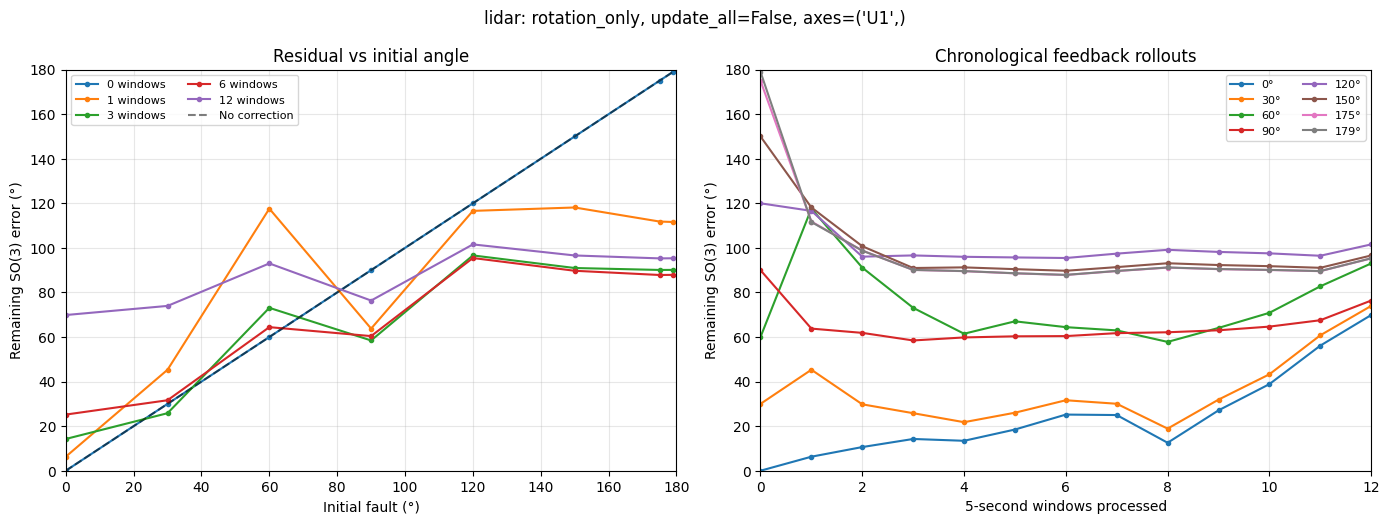

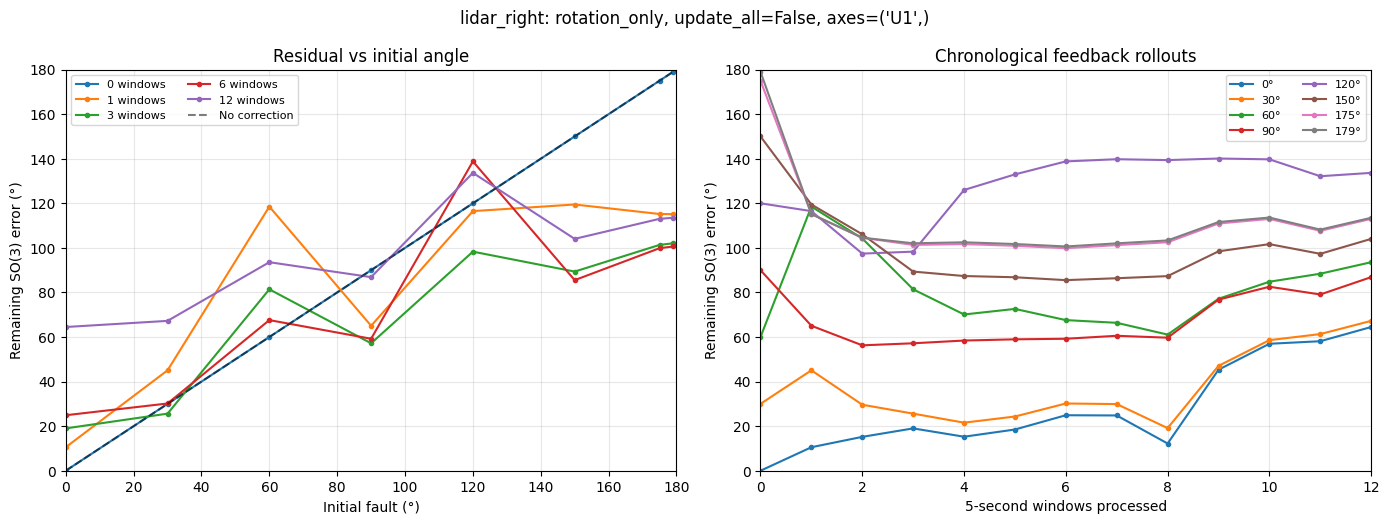

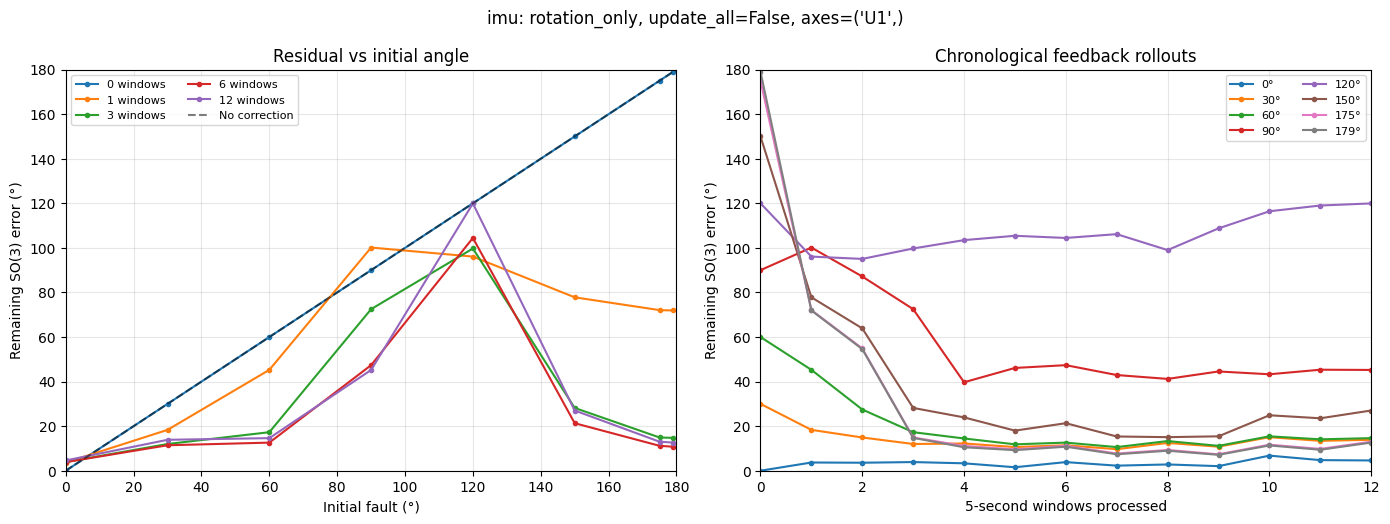

Saved rollout cases, summaries and figures under: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_large_paired_003.3_3d_large/plots/so3_correction_diagnostics
Evaluation only: model parameters, optimizer and scheduler were not updated.


In [60]:
# Chronological-feedback rollouts with exact initial rotation faults.
# Unlike applying a network repeatedly to one window, every step uses the NEXT physical KAIST window.

def diag65_update_from_predictions(states, predictions, fault_key):
    update_keys = set(CALIBRATION_KEYS if ROLL65_UPDATE_ALL_KEYS else (fault_key,))
    updated = {}
    for key, state in states.items():
        if key not in update_keys:
            updated[key] = state
            continue
        pred = predictions[key]
        if ROLL65_UPDATE_MODE == 'rotation_only':
            transform = state.transform.clone()
            transform[:, :3, :3] = so3_exp(pred.delta_xi[:, :3]) @ state.transform[:, :3, :3]
            updated[key] = CalibrationState(transform=transform, time_offset=state.time_offset.clone())
        else:
            updated[key] = CalibrationState(transform=se3_exp(pred.delta_xi) @ state.transform, time_offset=state.time_offset + pred.delta_tau)
    return updated


@torch.inference_mode()
def diag65_run_rollouts():
    rows = []
    was_training = model.training
    model.eval()
    try:
        for sequence_number, sequence_name in enumerate(ROLL65_SEQUENCES):
            all_indices = np.asarray(val_dataset.window_indices_for_sequence(sequence_name), dtype=int)
            max_start = len(all_indices) - ROLL65_NUM_WINDOWS
            if max_start < 0:
                raise ValueError(f'{sequence_name} has {len(all_indices)} windows; need {ROLL65_NUM_WINDOWS}')
            starts = np.unique(np.linspace(0, max_start, min(ROLL65_STARTS_PER_SEQUENCE, max_start + 1)).round().astype(int))
            for start_number, start_pos in enumerate(starts):
                indices = all_indices[start_pos : start_pos + ROLL65_NUM_WINDOWS]
                physical_seed = ROLL65_PHYSICAL_SEED + sequence_number * 100_003 + start_number * 1_009
                physical_windows = []
                for index in indices:
                    raw = window_batch_to(collate_windows([val_dataset[int(index)]]), DEVICE, dtype=MODEL_DTYPE)
                    # Re-create the augmentation generator with the same seed for each window,
                    # so all chronological measurements share one fixed calibration truth.
                    physical = context_augmentation_pipeline(raw, generator=make_augmentation_generator(physical_seed)).augmented_window
                    physical_windows.append(physical)
                truth = diag65_copy_states(physical_windows[0].current_calibration)
                for physical in physical_windows[1:]:
                    for key in CALIBRATION_KEYS:
                        torch.testing.assert_close(physical.current_calibration[key].transform, truth[key].transform, atol=2e-5, rtol=2e-5)
                        torch.testing.assert_close(physical.current_calibration[key].time_offset, truth[key].time_offset, atol=2e-6, rtol=2e-6)

                for fault_key in ROLL65_FAULT_KEYS:
                    for axis_name in ROLL65_AXIS_NAMES:
                        axis = DIAG65_AXES[axis_name]
                        for angle in ROLL65_ANGLES_DEG:
                            for sign in ((1,) if angle == 0.0 else (-1, 1)):
                                xi = {key: torch.zeros(1, 6, device=DEVICE, dtype=MODEL_DTYPE) for key in CALIBRATION_KEYS}
                                tau = {key: torch.zeros(1, 1, device=DEVICE, dtype=MODEL_DTYPE) for key in CALIBRATION_KEYS}
                                xi[fault_key][:, :3] = sign * np.deg2rad(angle) * axis
                                initial = apply_prior_perturbation(truth, xi, tau)
                                states = diag65_copy_states(initial)
                                for step in range(ROLL65_NUM_WINDOWS + 1):
                                    R_active = states[fault_key].transform[:, :3, :3]
                                    R_truth = truth[fault_key].transform[:, :3, :3]
                                    active_error = float(diag65_rotation_distance_deg(R_active, R_truth)[0])
                                    healthy_errors = [float(diag65_rotation_distance_deg(states[k].transform[:, :3, :3], truth[k].transform[:, :3, :3])[0]) for k in CALIBRATION_KEYS if k != fault_key]
                                    rows.append(dict(sequence=sequence_name, start_index=int(indices[0]), key=fault_key, axis=axis_name,
                                                     sign=int(sign), initial_angle_deg=float(angle), step=int(step),
                                                     elapsed_s=float(step * WINDOW_STRIDE_S), residual_deg=active_error,
                                                     gain_from_start_deg=float(angle - active_error), healthy_mean_deg=float(np.mean(healthy_errors))))
                                    if step == ROLL65_NUM_WINDOWS:
                                        break
                                    inp = clone_window_with_calibration(physical_windows[step], states)
                                    predictions = window_step(inp).model_output.predictions
                                    states = diag65_update_from_predictions(states, predictions, fault_key)
                print(f'Completed rollouts: {sequence_name}, start={int(indices[0])}, axes={ROLL65_AXIS_NAMES}, update_mode={ROLL65_UPDATE_MODE}', flush=True)
    finally:
        model.train(was_training)
    return pd.DataFrame(rows)


roll65_df = diag65_run_rollouts()
roll65_df.to_csv(DIAG65_OUTPUT_DIR / 'rollout_cases.csv', index=False)
roll65_summary = roll65_df.groupby(['key', 'axis', 'initial_angle_deg', 'step'], as_index=False).agg(
    mean_residual_deg=('residual_deg', 'mean'), median_residual_deg=('residual_deg', 'median'),
    p90_residual_deg=('residual_deg', lambda x: np.percentile(x, 90)),
    success_10deg=('residual_deg', lambda x: (x < 10).mean()),
    fraction_improved=('gain_from_start_deg', lambda x: (x > 1e-4).mean()),
    healthy_mean_deg=('healthy_mean_deg', 'mean'), n=('residual_deg', 'size'))
roll65_summary.to_csv(DIAG65_OUTPUT_DIR / 'rollout_summary.csv', index=False)

print('Mean residual (°) at each stage. Values below the initial angle indicate improvement.')
stages = sorted(set((0, 1, 3, 6, ROLL65_NUM_WINDOWS)) & set(roll65_summary.step.unique()))
print(roll65_summary[roll65_summary.step.isin(stages)].pivot_table(
    index=['key', 'axis', 'initial_angle_deg'], columns='step', values='mean_residual_deg').round(1).to_string())
print('\nFinal convergence probabilities by sensor and initial angle:')
print(roll65_df[roll65_df.step == ROLL65_NUM_WINDOWS].groupby(['key', 'initial_angle_deg']).agg(
    final_mean_deg=('residual_deg', 'mean'), final_median_deg=('residual_deg', 'median'),
    improved_pct=('gain_from_start_deg', lambda x: 100 * (x > 1e-4).mean()),
    success_10deg_pct=('residual_deg', lambda x: 100 * (x < 10).mean()),
    n=('residual_deg', 'size')).round(2).to_string())

for key in ROLL65_FAULT_KEYS:
    subset = roll65_df[roll65_df.key == key]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.3))
    for step in stages:
        curve = subset[subset.step == step].groupby('initial_angle_deg', as_index=False).residual_deg.mean().sort_values('initial_angle_deg')
        axes[0].plot(curve.initial_angle_deg, curve.residual_deg, '-o', markersize=3, label=f'{step} windows')
    axes[0].plot([0, 180], [0, 180], 'k--', alpha=0.5, label='No correction')
    axes[0].set(title='Residual vs initial angle', xlabel='Initial fault (°)', ylabel='Remaining SO(3) error (°)', xlim=(0, 180), ylim=(0, 180))
    for angle in ROLL65_ANGLES_DEG:
        curve = subset[subset.initial_angle_deg == angle].groupby('step', as_index=False).residual_deg.mean().sort_values('step')
        axes[1].plot(curve.step, curve.residual_deg, '-o', markersize=3, label=f'{angle:g}°')
    axes[1].set(title='Chronological feedback rollouts', xlabel='5-second windows processed', ylabel='Remaining SO(3) error (°)', xlim=(0, ROLL65_NUM_WINDOWS), ylim=(0, 180))
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, ncol=2)
    fig.suptitle(f'{key}: {ROLL65_UPDATE_MODE}, update_all={ROLL65_UPDATE_ALL_KEYS}, axes={ROLL65_AXIS_NAMES}')
    fig.tight_layout()
    fig.savefig(DIAG65_OUTPUT_DIR / f'{key}_rollouts.png', dpi=160)
    plt.show()

print('Saved rollout cases, summaries and figures under:', DIAG65_OUTPUT_DIR)
print('Evaluation only: model parameters, optimizer and scheduler were not updated.')


In [61]:
torch.cuda.empty_cache()